# Mərhələ 5: Xətti Reqressiya Modelləşdirməsi

## Məqsədlər

Bu mərhələdə siz:

1. Təmizlənmiş və xüsusiyyət mühəndisliyi aparılmış verilənlər dəstinizi yükləyib hazırlayacaqsınız
2. Verilənləri təlim (training) və test dəstlərinə bölməyi öyrənəcəksiniz
3. Xətti Reqressiya modeli quracaq və öyrədəcəksiniz
4. Həm təlim, həm də test verilənləri üzərində proqnozlar verəcəksiniz
5. Modelin performansını bir neçə metrikdən istifadə edərək qiymətləndirəcəksiniz
6. Proqnozları faktiki dəyərlərlə müqayisə edərək vizuallaşdıracaqsınız
7. Qalıqları (residuals) təhlil edib təkmilləşdirmə sahələrini müəyyən edəcəksiniz
8. Tapıntılarınızı və nəticələrinizi sənədləşdirəcəksiniz

## Təlimatlar

Ev qiymətlərini proqnozlaşdırmaq üçün öyrəndiyiniz Çoxdəyişənli Xətti Reqressiya (Multiple Linear Regression) üsullarını tətbiq edin. Hər tapşırığı addım-addım izləyin və TODO bölmələrini öz kodunuzla doldurun.

---
## Tapşırıq 1: Tələb Olunan Kitabxanaların İdxalı

In [32]:
# TODO: Tələb olunan kitabxanaları idxal edin:
# - import pandas as pd
# - import numpy as np
# - import matplotlib.pyplot as plt
# - import seaborn as sns
# - from sklearn.model_selection import train_test_split
# - from sklearn.linear_model import LinearRegression
# - from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
# - import warnings
# - warnings.filterwarnings('ignore')
import time
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split , cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error , mean_squared_error , r2_score
from sklearn.preprocessing import PolynomialFeatures,StandardScaler
import warnings
warnings.filterwarnings("ignore")
from scipy import stats
# TODO: Vizuallaşdırma üslubunu təyin edin:
# - sns.set_style('whitegrid')
# - plt.rcParams['figure.figsize'] = (12, 6)

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12 , 6)

# TODO: Bitdikdə uğur mesajını çap edin
print("Kitabxanalar uğurla yükləndi.")

Kitabxanalar uğurla yükləndi.


---
## Tapşırıq 2: Verilənlər Dəstinin Yüklənməsi və Araşdırılması

In [33]:
# TODO: Təmizlənmiş və xüsusiyyət mühəndisliyi aparılmış verilənlər dəstinizi yükləyin
# - 'train_feature_engineered.csv' və ya 'train_cleaned.csv' faylını yükləmək üçün pd.read_csv() istifadə edin
# - 'df' dəyişənində saxlayın

# DÜZƏLİŞ (xətanın əsl səbəbi): LinearRegression yalnız RƏQƏM qəbul edir.
# train_feature_engineered.csv (və train_cleaned.csv) oxunaqlı olsun deyə 34-39 MƏTN sütunu saxlayır
# (MSZoning='RL', Neighborhood='CollgCr', ExterQual='Gd' ...). Əvvəlki kod bu faylı oxuyub birbaşa fit edirdi və
# model.fit(...) "ValueError: could not convert string to float: 'RL'" ilə dayanırdı.
# 3-cü notebook-un sonunda həmin mətnlər ədədə çevrilib (ordinal + one-hot) train_model_ready.csv-ə yazılır — modelə onu veririk.
df = pd.read_csv('train_model_ready.csv')

# Qoruyucu yoxlama: modelə mətn sütunu getməsin (getsə, xəta fit-də yox, burada və aydın mesajla çıxsın)
text_cols = df.select_dtypes(exclude='number').columns.tolist()
assert not text_cols, f"Modelə mətn sütunu verilə bilməz: {text_cols}"

# TODO: Verilənlər dəsti haqqında məlumatı göstərin
# - Ölçünü çap edin: df.shape
# - Sütun adlarını çap edin: df.columns
# - İlk bir neçə sətri çap edin: df.head()
# - Verilənlər tiplərini çap edin: df.dtypes
# - Çatışmayan dəyərləri çap edin: df.isnull().sum()
print("Ölçü (sətir, sütun):", df.shape)
print("\nSütun adları:")
print(df.columns.tolist())
print("\nİlk bir neçə sətir:")
print(df.head())
print("\nVerilənlər tipləri:")
print(df.dtypes)
print("\nÇatışmayan dəyərlər:")
print(df.isna().sum().sum())


Ölçü (sətir, sütun): (1458, 190)

Sütun adları:
['LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'HeatingQC', '2ndFlrSF', 'LowQualFinSF', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'TotalSF', 'Slope_to_LotArea', 'IsNew', 'HasFireplace', 'HasPorch', 'Quality_x_Area', 'Quality_x_Condition', 'MSSubClass_MS160', 'MSSubClass_MS180', 'MSSubClass_MS190', 'MSSubClass_MS20', 'MSSubClass_MS30', 'MSSubClass_MS40', 'MSSubClass_MS45', 'MSSubClass_MS50', 'MSSubClass_MS60', 'MSSubClass_MS70', 'MSSubClass_MS75', '

---
## Tapşırıq 3: Xüsusiyyətlərin və Hədəf Dəyişənin Hazırlanması

In [34]:
# TODO: Xüsusiyyətləri (X) və hədəf dəyişəni (y) ayırın
# - X 'SalePrice' istisna olmaqla bütün sütunları ehtiva etməlidir
# - y yalnız 'SalePrice' sütununu ehtiva etməlidir
# - İstifadə edin: X = df.drop('SalePrice', axis=1)
# - İstifadə edin: y = df['SalePrice']

# DÜZƏLİŞ: Id sətir nömrəsidir, evin xüsusiyyəti deyil — modelə verilməməlidir.
# (train_model_ready.csv-də artıq yoxdur; başqa fayl yüklənərsə qoruyucu kimi qalır.)
X = df.drop(columns=["SalePrice", "Id"], errors="ignore")
y = df['SalePrice']

# TODO: Ayrılmanı yoxlayın
# - X.shape çap edin
# - y.shape çap edin
# - Sütun sayının uyğun gəldiyini çap edin

print(X.shape)
print(y.shape)



(1458, 189)
(1458,)


---
## Tapşırıq 4: Verilənlərin Təlim və Test Dəstlərinə Bölünməsi

In [35]:
# TODO: Verilənləri təlim (80%) və test (20%) dəstlərinə bölün
# - İstifadə edin: train_test_split(X, y, test_size=0.2, random_state=42)
# - Saxlayın: X_train, X_test, y_train, y_test

X_train , X_test , y_train , y_test = train_test_split(X , y , test_size=0.2 , random_state=42)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)


# TODO: Bölünməni yoxlayın
# - X_train.shape, X_test.shape çap edin
# - y_train.shape, y_test.shape çap edin
# - Faizlərin düzgün cəmləndiyini yoxlayın

train_pct = X_train.shape[0] / X.shape[0] * 100
test_pct = X_test.shape[0] / X.shape[0] * 100
print(f"\nTəlim faizi: {train_pct:.1f}%")
print(f"Test faizi : {test_pct:.1f}%")
print(f"Cəm : {train_pct + test_pct:.1f}%")


X_train: (1166, 189)
X_test : (292, 189)
y_train: (1166,)
y_test : (292,)

Təlim faizi: 80.0%
Test faizi : 20.0%
Cəm : 100.0%


In [ ]:
binary = [c for c in X_train.columns if set(X_train[c].unique()) <= {0, 1}]
rare   = [c for c in binary if X_train[c].sum() < 10]
X_train, X_test = X_train.drop(columns=rare), X_test.drop(columns=rare)
print(f"Silinən sütun sayı: {len(rare)}")

Silinən sütun sayı: 38


---
## Tapşırıq 5: Xətti Reqressiya Modelinin Qurulması və Öyrədilməsi

In [37]:
# TODO: Xətti Reqressiya modeli yaradın
# - İstifadə edin: model = LinearRegression()
model = LinearRegression()

# TODO: Modeli təlim verilənləri üzərində öyrədin
# - İstifadə edin: model.fit(X_train, y_train)

model.fit(X_train , y_train)

# TODO: Model haqqında məlumatı göstərin
# - Xüsusiyyətlərin sayını çap edin
# - Modelin əmsallarını (coefficients) çap edin (ilk 10)
# - Modelin kəsişmə nöqtəsini (intercept) çap edin

print("Feature sayi: " , len(model.coef_))
print("İlk 10 coefficient:", model.coef_[:10])
print("Intercept:", model.intercept_)


Feature sayi:  151
İlk 10 coefficient: [ 6.00466461e+01  4.99803852e-01 -2.35999273e+04  4.25209552e+03
  2.97172590e+02  5.02196345e+01  2.26130489e+01  1.91647442e+03
 -5.42389951e+03  2.13124622e+03]
Intercept: -1294620.1445382885


---
## Tapşırıq 6: Proqnozların Verilməsi

In [38]:
# TODO: Təlim verilənləri üzərində proqnozlar verin
# - İstifadə edin: y_train_pred = model.predict(X_train)

y_train_pred = model.predict(X_train)

# TODO: Test verilənləri üzərində proqnozlar verin
# - İstifadə edin: y_test_pred = model.predict(X_test)

y_test_pred = model.predict(X_test)

# TODO: Nümunə proqnozları göstərin
# - [Actual, Predicted, Difference] sütunları olan müqayisə DataFrame-i yaradın
# - Təlim dəsti üçün ilk 10 sətri göstərin
# - Test dəsti üçün ilk 10 sətri göstərin



train_comparison = pd.DataFrame({
    'Actual' : y_train.values,
    'Predicted': y_train_pred ,
    "Difference" : y_train.values - y_train_pred
})

test_comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_test_pred,
    'Difference': y_test.values - y_test_pred
})

print("Təlim dəsti - ilk 10 sətir:")
print(train_comparison.head(10))

# Test dəsti üçün ilk 10 sətir
print("\nTest dəsti - ilk 10 sətir:")
print(test_comparison.head(10))


Təlim dəsti - ilk 10 sətir:
   Actual      Predicted    Difference
0  145000  146085.344088  -1085.344088
1  178000  172811.336514   5188.663486
2  148500  137071.347047  11428.652953
3  175000  157267.484519  17732.515481
4  127000  155313.997471 -28313.997471
5  149900  141250.710795   8649.289205
6  174000  189615.348121 -15615.348121
7  125500  132987.133957  -7487.133957
8  175500  175732.020399   -232.020399
9  225000  243997.653980 -18997.653980

Test dəsti - ilk 10 sətir:
   Actual      Predicted    Difference
0  190000  226862.154038 -36862.154038
1  100000   91744.730089   8255.269911
2  115000   93989.107536  21010.892464
3  159000  158394.590865    605.409135
4  315500  294938.504257  20561.495743
5  137500  142200.837254  -4700.837254
6  311500  233358.273489  78141.726511
7  310000  314455.776268  -4455.776268
8  281000  315648.308015 -34648.308015
9  135500  140321.491192  -4821.491192


---
## Tapşırıq 7: Modelin Performansının Qiymətləndirilməsi

### Qiymətləndirmə Metrikləri İzah Olunur:

- **MSE (Mean Squared Error - Orta Kvadratik Xəta)**: Kvadratik xətaların ortası. Böyük xətaları daha ağır cəzalandırır.
- **RMSE (Root Mean Squared Error - Orta Kvadratik Xətanın Kökü)**: MSE-nin kvadrat kökü. Hədəf dəyişənlə eyni vahiddədir (qiymət).
- **MAE (Mean Absolute Error - Orta Mütləq Xəta)**: Mütləq xətaların ortası. MSE-dən daha intuitivdir.
- **R² (R-Kvadrat)**: Determinasiya əmsalı. İzah olunan dispersiyanın payı (0-dan 1-ə qədər). Nə qədər yüksəkdirsə, o qədər yaxşıdır.

In [39]:
# TODO: TƏLİM verilənləri üçün qiymətləndirmə metriklərini hesablayın
# - MSE: mean_squared_error(y_train, y_train_pred)
# - RMSE: np.sqrt(MSE)
# - MAE: mean_absolute_error(y_train, y_train_pred)
# - R²: r2_score(y_train, y_train_pred)

train_mse = mean_squared_error(y_train , y_train_pred)
train_rmse = np.sqrt(train_mse)
train_mae = mean_absolute_error(y_train , y_train_pred)
train_r2 = r2_score(y_train , y_train_pred)


# TODO: TEST verilənləri üçün qiymətləndirmə metriklərini hesablayın
# - Yuxarıdakı ilə eyni metriklər, lakin y_test və y_test_pred istifadə edilir
test_mae = mean_absolute_error(y_test , y_test_pred)
test_mse = mean_squared_error(y_test , y_test_pred)
test_r2 = r2_score(y_test , y_test_pred)
test_rmse = np.sqrt(test_mse)

# TODO: Nəticələri formatlanmış cədvəldə çap edin
# - Təlim və Test metrikləri ilə nəticə DataFrame-i yaradın
# - Düzgün formatlaşdırma ilə aydın göstərin (RMSE/MAE üçün valyuta formatı)


results_df = pd.DataFrame({
    'Metrik': ['MSE', 'RMSE', 'MAE', 'R²'],
    'Təlim': [
        f"${train_mse:,.2f}",
        f"${train_rmse:,.2f}",
        f"${train_mae:,.2f}",
        f"{train_r2:.4f}"
    ],
    'Test': [
        f"${test_mse:,.2f}",
        f"${test_rmse:,.2f}",
        f"${test_mae:,.2f}",
        f"{test_r2:.4f}"
    ]
})

print("=" * 45)
print("MODELİN QİYMƏTLƏNDİRMƏ NƏTİCƏLƏRİ")
print("=" * 45)
print(results_df.to_string(index=False))
print("=" * 45)


MODELİN QİYMƏTLƏNDİRMƏ NƏTİCƏLƏRİ
Metrik           Təlim            Test
   MSE $371,664,329.98 $553,892,007.92
  RMSE      $19,278.60      $23,534.91
   MAE      $13,610.36      $16,316.23
    R²          0.9429          0.8997


---
## Tapşırıq 8: Nəticələrin Vizuallaşdırılması

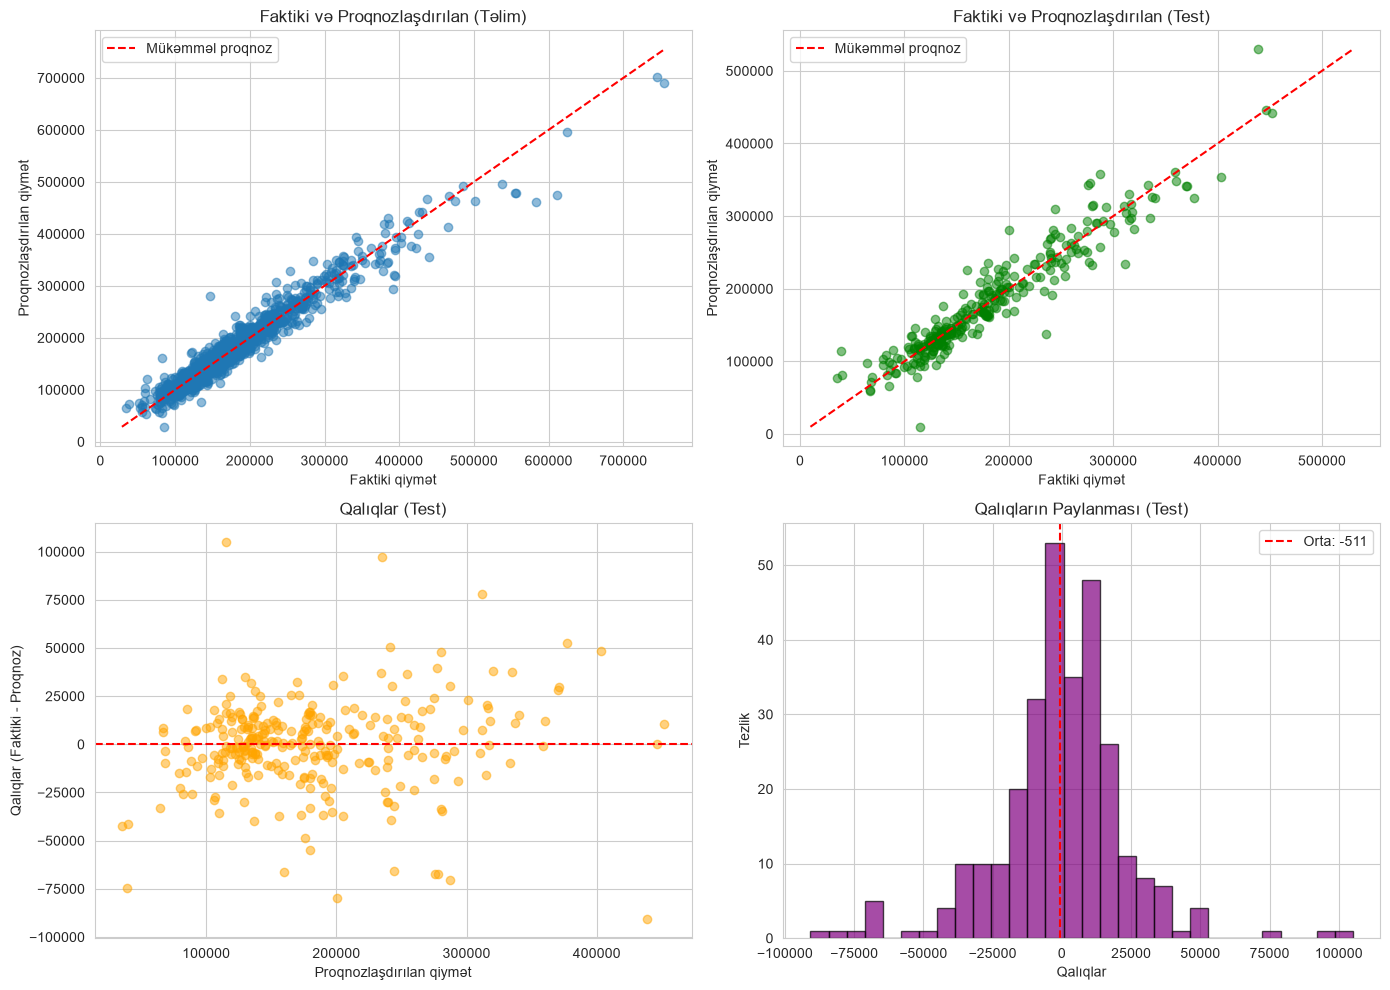

In [40]:
# TODO: Modelin qiymətləndirilməsinin vizuallaşdırılması üçün 2x2 subplot yaradın
# 
# Subplot 1: Faktiki və Proqnozlaşdırılan (Təlim)
# - Scatter plot: X=Actual, Y=Predicted (təlim verilənlərindən istifadə edin)
# - Diaqonal xətt əlavə edin (mükəmməl proqnoz)
# - Oxların adları və başlıq

fig , axes = plt.subplots(2 , 2 , figsize = (14, 10))

axes[0 , 0].scatter(y_train , y_train_pred , alpha = 0.5)
min_val = min(y_train.min() , y_train_pred.min())
max_val = max(y_train.max() , y_train_pred.max())
axes[0, 0].plot([min_val , max_val] , [min_val , max_val] , 'r--' , label='Mükəmməl proqnoz')
axes[0, 0].set_xlabel('Faktiki qiymət')
axes[0, 0].set_ylabel('Proqnozlaşdırılan qiymət')
axes[0, 0].set_title('Faktiki və Proqnozlaşdırılan (Təlim)')
axes[0, 0].legend()



# Subplot 2: Faktiki və Proqnozlaşdırılan (Test)
# - Scatter plot: X=Actual, Y=Predicted (test verilənlərindən istifadə edin)
# - Diaqonal xətt əlavə edin (mükəmməl proqnoz)
# - Oxların adları və başlıq

axes[0, 1].scatter(y_test, y_test_pred, alpha=0.5, color='green')
min_val = min(y_test.min(), y_test_pred.min())
max_val = max(y_test.max(), y_test_pred.max())
axes[0, 1].plot([min_val, max_val], [min_val, max_val], 'r--', label='Mükəmməl proqnoz')
axes[0, 1].set_xlabel('Faktiki qiymət')
axes[0, 1].set_ylabel('Proqnozlaşdırılan qiymət')
axes[0, 1].set_title('Faktiki və Proqnozlaşdırılan (Test)')
axes[0, 1].legend()

# Subplot 3: Qalıqlar (Test)
# - Qalıqları hesablayın: residuals = y_test - y_test_pred
# - Scatter plot: X=y_test_pred, Y=residuals
# - y=0 nöqtəsində üfüqi xətt əlavə edin
# - Oxların adları və başlıq

residuals = y_test - y_test_pred

axes[1,0].scatter(y_test, residuals , alpha = 0.5 , color = 'orange')
axes[1,0].axhline(y = 0  , color = 'r' , linestyle = '--')
axes[1, 0].set_xlabel('Proqnozlaşdırılan qiymət')
axes[1, 0].set_ylabel('Qalıqlar (Faktiki - Proqnoz)')
axes[1, 0].set_title('Qalıqlar (Test)')

# Subplot 4: Qalıqların Paylanması (Test)
# - Qalıqların histoqramı
# - Qalıqların ortasında şaquli xətt əlavə edin
# - Oxların adları və başlıq
axes[1, 1].hist(residuals, bins=30, color='purple', alpha=0.7, edgecolor='black')
axes[1, 1].axvline(x=residuals.mean(), color='r', linestyle='--',
                label=f'Orta: {residuals.mean():,.0f}')
axes[1, 1].set_xlabel('Qalıqlar')
axes[1, 1].set_ylabel('Tezlik')
axes[1, 1].set_title('Qalıqların Paylanması (Test)')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

---
## Tapşırıq 9: Qalıqların və Modelin Performansının Təhlili

In [41]:
# TODO: Qalıqları təhlil edin
# - Qalıqların statistikasını hesablayın
# - Qalıqların ortası (0-a yaxın olmalıdır)
# - Qalıqların standart sapması
# - Qalıqların minimum və maksimumu
# - Heteroskedastiklik (artan dispersiya) olub-olmadığını yoxlayın

residual = np.asarray(y_test) - np.asarray(y_test_pred)
y_pred_arr = np.asarray(y_test_pred).ravel() 
print("=" * 50)
print("QALIQLARIN STATİSTİKASI (TEST)")
print("=" * 50)
print(f"Orta (0-a yaxın olmalıdır):{residuals.mean():,.2f}")
print(f"Standart sapma:{residuals.std():,.2f}")
print(f"Minimum:{residuals.min():,.2f}")
print(f"Maksimum:{residuals.max():,.2f}")

corr , p_value = stats.spearmanr(y_pred_arr , np.abs(residual))
print(f"\nHeteroskedastiklik yoxlaması:")
print(f"Spearman korrelyasiyası (proqnoz vs |qalıq|): {corr:.3f} (p={p_value:.4f})")

if p_value < 0.05 and corr > 0.2:
    print("\n→ Heteroskedastiklik VAR: proqnoz artdıqca səhvlər də artır.")
else:
    print("\n→ Heteroskedastiklik zəifdir və ya yoxdur.")

# TODO: Modelin performansını təhlil edin
# - Təlim və test R² qiymətlərini müqayisə edin (həddindən artıq uyğunlaşma - overfitting - aşkarlanması)
# - RMSE-nin sizin istifadə halınız üçün məqbul olub-olmadığını yoxlayın
# - Ən böyük xətaları (ən pis proqnozları) müəyyən edin


print("\n" + "=" * 50)
print("MODELİN PERFORMANSI")
print("=" * 50)

r2_gap = train_r2 - test_r2
print(f"Train R²: {train_r2:.4f}")
print(f"Test R²:  {test_r2:.4f}")
print(f"Fərq:{r2_gap:.4f}")

if r2_gap < 0.05:
    print("→ Overfitting yoxdur və ya çox zəifdir.")
elif r2_gap < 0.1:
    print("→ Yüngül overfitting.")
else:
    print("→ Ciddi overfitting. Regulyarizasiya tövsiyə olunur.")

mean_price = np.mean(y_test)
print(f"\nTest RMSE: ${test_rmse:,.2f}")
print(f"Test MAE:  ${test_mae:,.2f}")
print(f"Orta qiymət: ${mean_price:,.2f}")
print(f"RMSE / orta qiymət: {test_rmse / mean_price * 100:.1f}%")
print(f"MAE  / orta qiymət: {test_mae / mean_price * 100:.1f}%")

comparison = pd.DataFrame({
    'Actual': np.asarray(y_test),
    'Predicted': y_pred_arr,
    'Difference': residuals
})
comparison['Abs_Error'] = comparison['Difference'].abs()
comparison['Pct_Error'] = comparison['Abs_Error'] / comparison['Actual'] * 100
print("\n" + "=" * 50)
print("ƏN BÖYÜK 10 XƏTA (mütləq dəyərə görə)")
print("=" * 50)
print(comparison.sort_values('Abs_Error', ascending=False).head(10).round(2).to_string())
print("\nƏN BÖYÜK 10 XƏTA (faizlə)")
print(comparison.sort_values('Pct_Error', ascending=False).head(10).round(2).to_string())


QALIQLARIN STATİSTİKASI (TEST)
Orta (0-a yaxın olmalıdır):-510.71
Standart sapma:23,569.76
Minimum:-90,807.02
Maksimum:105,077.65

Heteroskedastiklik yoxlaması:
Spearman korrelyasiyası (proqnoz vs |qalıq|): 0.190 (p=0.0011)

→ Heteroskedastiklik zəifdir və ya yoxdur.

MODELİN PERFORMANSI
Train R²: 0.9429
Test R²:  0.8997
Fərq:0.0432
→ Overfitting yoxdur və ya çox zəifdir.

Test RMSE: $23,534.91
Test MAE:  $16,316.23
Orta qiymət: $181,369.45
RMSE / orta qiymət: 13.0%
MAE  / orta qiymət: 9.0%

ƏN BÖYÜK 10 XƏTA (mütləq dəyərə görə)
      Actual  Predicted  Difference  Abs_Error  Pct_Error
107   115000    9922.35   105077.65  105077.65      91.37
1157  235128  138020.19    97107.81   97107.81      41.30
58    438780  529587.02   -90807.02   90807.02      20.70
528   200624  280175.69   -79551.69   79551.69      39.65
218   311500  233358.27    78141.73   78141.73      25.09
532    39300  113665.66   -74365.66   74365.66     189.23
1023  287000  357414.00   -70414.00   70414.00      24.53
1

---
## Tapşırıq 10: Xülasə və Təhlil - Bu Suallara Cavab Verin

### Modelin Performansı ilə Bağlı Suallar:

1. **Modelin Ümumi Keyfiyyəti**
   - Test dəstində R² qiymətiniz nədir?
   - RMSE dollarla nə qədərdir?
   - Bu yaxşı modeldirmi? Niyə və ya niyə yox?

2. **Ümumiləşdirmə (Generalization)**
   - Təlim R² və test R² qiymətlərini müqayisə edin. 
   - Əhəmiyyətli fərq varmı? (Overfitting/underfitting olduğunu göstərir)
   - Hansı verilənlər dəsti daha yaxşı nəticə göstərir?

3. **Proqnozun Dəqiqliyi**
   - Orta hesabla proqnozlarınız nə qədər yanlışdır (MAE)?
   - Bu, verilənlərinizin neçə faizini təşkil edir?
   - Bu, sizin istifadə halınız üçün məqbuldurmu?

4. **Qalıqların Təhlili**
   - Qalıqlar sıfır ətrafında təsadüfi paylanıbmı?
   - Qalıqlar qrafikində hər hansı qanunauyğunluq görünürmü?
   - Bu, modeliniz haqqında sizə nə deyir?

5. **Ən Pis Proqnozlar**
   - Modeliniz hansı tip evləri zəif proqnozlaşdırır?
   - Böyük xətaların ortaq xüsusiyyətlərini müəyyən edə bilərsinizmi?

6. **Xüsusiyyət Əlaqələri**
   - Sizcə, hansı xüsusiyyətlərin qiymətlə ən güclü əlaqəsi var?
   - Elə xüsusiyyətlər varmı ki, bu qədər vacib olmamalı idi?

### Təhlilinizi BURAYA yazın:

(Bunu modelin performansı barədə yazılı təhlilinizlə əvəz edin)

---
## BONUS Tapşırıq 1: Xüsusiyyətlərin Əhəmiyyətinin Təhlili

Xüsusiyyətlərin əhəmiyyəti (feature importance) hansı xüsusiyyətlərin ev qiymətlərinə ən güclü təsir etdiyini göstərir.

### TODO: Xüsusiyyət Əmsallarını Çıxarın və Vizuallaşdırın
```python
# TODO: Modelin əmsallarını çıxarın
# - İstifadə edin: coefficients = model.coef_
# - İstifadə edin: feature_names = X_train.columns

# TODO: Xüsusiyyətlər və onların əmsalları ilə DataFrame yaradın
# - 'Feature' və 'Coefficient' sütunları ilə dataframe yaradın
# - Əmsalın mütləq qiymətinə görə düzün (azalan)
# - İlk 10 və son 10 xüsusiyyəti göstərin

# TODO: Ən vacib ilk 10 xüsusiyyəti vizuallaşdırın
# - Əmsal dəyərlərini göstərən barplot istifadə edin
# - Müsbət (qiyməti artırır) və mənfi (qiyməti azaldır) əmsallar üçün fərqli rənglər istifadə edin
# - Oxların adlarını və başlıq əlavə edin

# TODO: Nəticələri şərh edin
# - Hansı xüsusiyyətlərin qiymətə ən güclü müsbət təsiri var?
# - Hansı xüsusiyyətlərin qiymətə ən güclü mənfi təsiri var?
# - Bu, ev qiymətləndirməsi baxımından məntiqlidirmi?
```

---
## BONUS Tapşırıq 2: Çarpaz Yoxlama (Cross-Validation)

Çarpaz yoxlama modelin performansını bir neçə fərqli verilən bölgüsü üzərində sınaqdan keçirir.

### TODO: 5-Qat Çarpaz Yoxlama Aparın
```python
# TODO: sklearn.model_selection-dan cross_val_score idxal edin

# TODO: 5-qat çarpaz yoxlama aparın
# - İstifadə edin: cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='r2')
# - cv_scores-un ortasını və standart sapmasını hesablayın

# TODO: Test dəstinin performansı ilə müqayisə edin
# - Təlim R² çap edin: r2_score(y_train, y_train_pred)
# - Test R² çap edin: r2_score(y_test, y_test_pred)
# - Çarpaz yoxlamanın ortasını və standart sapmasını çap edin
# - Onlar oxşardırmı? (yaxşı ümumiləşdirmə) yoxsa fərqlidir? (overfitting/underfitting)

# TODO: Təhlil
# - Hər bir CV qatı sizə nə deyir?
# - Modelinizin performansı fərqli verilən bölgülərində ardıcıldırmı?
```

---
## BONUS Tapşırıq 3: Polinomial Xüsusiyyətlər

Polinomial xüsusiyyətlər qeyri-xətti əlaqələri əks etdirə bilər.

### TODO: Polinomial Xüsusiyyətləri Sınaqdan Keçirin
```python
# TODO: sklearn.preprocessing-dən PolynomialFeatures idxal edin

# TODO: Polinomial xüsusiyyətlər yaradın (degree=2)
# - İstifadə edin: poly = PolynomialFeatures(degree=2, include_bias=False)
# - İstifadə edin: X_train_poly = poly.fit_transform(X_train)
# - İstifadə edin: X_test_poly = poly.transform(X_test)

# TODO: Modeli polinomial xüsusiyyətlər üzərində öyrədin
# - Yeni LinearRegression modeli yaradın
# - X_train_poly və y_train üzərində fit edin
# - X_test_poly üzərində proqnozlar verin

# TODO: Performansı müqayisə edin
# - Polinomial model üçün R² qiymətini hesablayın (test)
# - Xətti modelin R² qiyməti ilə müqayisə edin
# - Yaxşılaşdımı? Nə qədər?

# TODO: Overfitting-i yoxlayın
# - Polinomial model üçün təlim və test R² qiymətlərini müqayisə edin
# - Polinomial model xətti modeldən daha çox overfitting edirmi?

# TODO: Təhlil
# - Polinomial reqressiya bu verilənlər dəsti üçün daha yaxşıdırmı?
# - Hansı bahasına? (artan mürəkkəblik, daha çox xüsusiyyət, təlim vaxtı)
```

---
## BONUS Tapşırıq 4: Xüsusiyyətlərin Miqyaslanması (Feature Scaling)

Miqyaslama xüsusiyyətləri oxşar aralıqlara gətirir və bu, bəzi modellərə təsir edə bilər.

### TODO: Xüsusiyyətlərin Miqyaslanmasını Sınaqdan Keçirin
```python
# TODO: sklearn.preprocessing-dən StandardScaler idxal edin

# TODO: Miqyaslayıcı yaradın və təlim verilənləri üzərində fit edin
# - İstifadə edin: scaler = StandardScaler()
# - İstifadə edin: X_train_scaled = scaler.fit_transform(X_train)
# - İstifadə edin: X_test_scaled = scaler.transform(X_test)

# TODO: LinearRegression-ı miqyaslanmış xüsusiyyətlər üzərində öyrədin
# - Yeni LinearRegression modeli yaradın
# - X_train_scaled və y_train üzərində fit edin
# - X_test_scaled üzərində proqnozlar verin

# TODO: Miqyaslanmamış modellə müqayisə edin
# - Miqyaslanmış model üçün R² qiymətini hesablayın (test)
# - Orijinal (miqyaslanmamış) modelin R² qiyməti ilə müqayisə edin
# - Miqyaslama R² qiymətini dəyişdirdimi?

# TODO: Təlim vaxtını ölçün (könüllü)
# - İstifadə edin: import time
# - Miqyaslanmış və miqyaslanmamış modellərin təlim vaxtını müqayisə edin
# - Biri digərindən daha sürətlidirmi?

# TODO: Təhlil
# - Miqyaslama LinearRegression-ın performansına təsir edirmi? (İpucu: Çox təsir etməməlidir)
# - Miqyaslama nə vaxt vacib olardı? (KNN, SVM, Neyron Şəbəkələri)
# - Miqyaslanmış əmsallar fərqli olaraq nəyi ifadə edir?
```

---
## BONUS Tapşırıq 5: Kaggle Test Dəstində Proqnozlar

Kaggle-a təqdimat üçün faktiki test dəsti üzərində proqnozlar verin.

### TODO: Kaggle Təqdimatı Yaradın
```python
# TODO: Test dəstini yükləyin
# - İstifadə edin: test_df = pd.read_csv('test.csv')
# - 'Id' sütununu ayrıca saxlayın

# TODO: Test verilənlərini təlim verilənləri ilə eyni qaydada ön işləyin
# - Təlim verilənlərindəki ilə eyni xüsusiyyət mühəndisliyini tətbiq edin
# - Əgər istifadə etmisinizsə, eyni miqyaslayıcını (scaler) istifadə edin
# - Eyni xüsusiyyətlərin seçildiyindən əmin olun

# TODO: Test dəsti üzərində proqnozlar verin
# - İstifadə edin: test_predictions = model.predict(test_features)
# - Bunlar sizin proqnozlaşdırdığınız ev qiymətləridir

# TODO: Təqdimat DataFrame-i yaradın
# - 'Id' və 'SalePrice' sütunları ilə dataframe yaradın
# - Orijinal test dəstinin ID-lərindən və proqnozlarınızdan istifadə edin
# - Çatışmayan dəyərlərin olmadığından əmin olun

# TODO: Təqdimat faylını yadda saxlayın
# - İstifadə edin: submission.to_csv('submission.csv', index=False)
# - Fayl formatını yoxlayın (belə olmalıdır: Id, SalePrice)
# - Qeyd: Qiymətləndirmə üçün onu Kaggle-a yükləyə bilərsiniz

# TODO: Təhlil
# - Proqnozlaşdırılan qiymət aralığı nədir?
# - Hansı evlər ən yüksək/ən aşağı proqnozlara malikdir?
# - Bu proqnozlara nə dərəcədə əminsiniz?
```


Ən vacib 10 xüsusiyyət:
              Feature  Coefficients
         SaleType_New  96132.666857
SaleCondition_Partial -72854.253880
          MSZoning_FV  42849.809028
          MSZoning_RL  35211.170788
          MSZoning_RH  32906.910569
 Neighborhood_StoneBr  29355.240016
          MSZoning_RM  28147.710208
          OverallQual -23599.927333
 Neighborhood_MeadowV -19565.351274
  Exterior1st_BrkFace  19228.088587

Ən az vacib 10 xüsusiyyət:
         Feature  Coefficients
Slope_to_LotArea     23.843097
    LotShape_Reg     23.075607
      MasVnrArea     22.613049
  Quality_x_Area     20.090019
        2ndFlrSF    -16.923367
        PoolArea     16.872275
      WoodDeckSF     12.471548
   EnclosedPorch      9.567276
         LotArea      0.499804
         MiscVal      0.210592


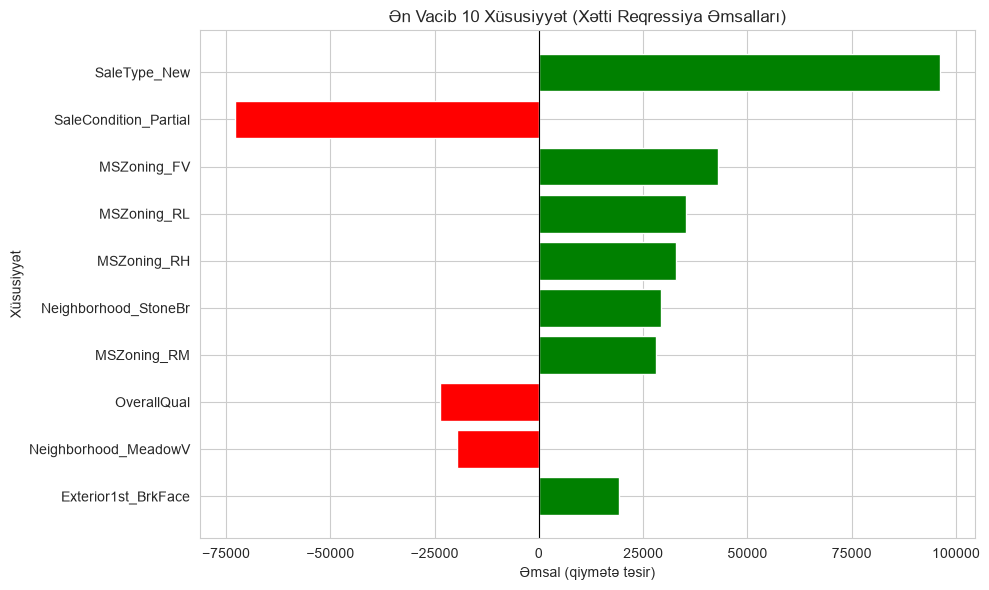

In [42]:
coefficients = np.ravel(model.coef_)
feature_names = X_train.columns

coef_df = pd.DataFrame({
    'Feature' : feature_names,
    'Coefficients' : coefficients
})

coef_df['Abs_Coefficient'] = coef_df['Coefficients'].abs()
coef_df = coef_df.sort_values('Abs_Coefficient', ascending=False).reset_index(drop=True)

print("Ən vacib 10 xüsusiyyət:")
print(coef_df.head(10)[['Feature', 'Coefficients']].to_string(index=False))

print("\nƏn az vacib 10 xüsusiyyət:")
print(coef_df.tail(10)[['Feature', 'Coefficients']].to_string(index=False))

top10 = coef_df.head(10).iloc[::-1]
colors = ['green' if c > 0 else 'red' for c in top10['Coefficients']]

plt.figure(figsize=(10 , 6))
plt.barh(top10['Feature'] , top10['Coefficients'] , color = colors)
plt.axvline(x = 0 , color = 'black' , linewidth = 0.8)
plt.xlabel('Əmsal (qiymətə təsir)')
plt.ylabel('Xüsusiyyət')
plt.title('Ən Vacib 10 Xüsusiyyət (Xətti Reqressiya Əmsalları)')
plt.tight_layout()
plt.show()



In [43]:
cv_scores = cross_val_score(model , X_train , y_train , cv=5 , scoring='r2')

cv_mean = cv_scores.mean()
cv_std =  cv_scores.std()

print("Hər qat üzrə R²:")
for i , score in enumerate(cv_scores , start=1):
    print(f"Qat {i}: {score:.4f}")

print(f"\nCV orta R²: {cv_mean:.4f}")
print(f"CV standart sapma: {cv_std:.4f}")


train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("\n" + "=" * 40)
print("MÜQAYİSƏ")
print("=" * 40)
print(f"Təlim R²: {train_r2:.4f}")
print(f"Test R²: {test_r2:.4f}")
print(f"CV orta R²: {cv_mean:.4f} (± {cv_std:.4f})")

Hər qat üzrə R²:
Qat 1: 0.9376
Qat 2: 0.9031
Qat 3: 0.9012
Qat 4: 0.9290
Qat 5: 0.8763

CV orta R²: 0.9094
CV standart sapma: 0.0218

MÜQAYİSƏ
Təlim R²: 0.9429
Test R²: 0.8997
CV orta R²: 0.9094 (± 0.0218)


In [44]:
poly = PolynomialFeatures(degree=2 , include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

print(f"Xüsusiyyət sayı (əvvəl): {X_train.shape[1]}")
print(f"Xüsusiyyət sayı (sonra): {X_train_poly.shape[1]}")

start = time.time()
poly_model = LinearRegression()
poly_model.fit(X_train_poly , y_train)
fit_time = time.time() - start

y_train_pred_poly = poly_model.predict(X_train_poly)
y_test_pred_poly = poly_model.predict(X_test_poly)

poly_train_r2 = r2_score(y_train, y_train_pred_poly)
poly_test_r2 = r2_score(y_test, y_test_pred_poly)
poly_test_rmse = np.sqrt(mean_squared_error(y_test,y_test_pred_poly))

lin_train_r2 = r2_score(y_train, y_train_pred)
lin_test_r2 = r2_score(y_test, y_test_pred)
lin_test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

print("\n" + "=" * 50)
print("MÜQAYİSƏ: Xətti vs Polinomial (degree=2)")
print("=" * 50)
print(f"{'':20}{'Xətti':>14}{'Polinomial':>14}")
print(f"{'Təlim R²':20}{lin_train_r2:>14.4f}{poly_train_r2:>14.4f}")
print(f"{'Test R²':20}{lin_test_r2:>14.4f}{poly_test_r2:>14.4f}")
print(f"{'Test RMSE':20}{lin_test_rmse:>14,.0f}{poly_test_rmse:>14,.0f}")

# 4) Yaxşılaşma və overfitting
print(f"\nTest R² dəyişikliyi: {poly_test_r2 - lin_test_r2:+.4f}")
print(f"Xətti model - Təlim/Test fərqi:      {lin_train_r2 - lin_test_r2:.4f}")
print(f"Polinomial model - Təlim/Test fərqi: {poly_train_r2 - poly_test_r2:.4f}")
print(f"Polinomial modelin öyrədilmə vaxtı:  {fit_time:.2f} san")

Xüsusiyyət sayı (əvvəl): 151
Xüsusiyyət sayı (sonra): 11627

MÜQAYİSƏ: Xətti vs Polinomial (degree=2)
                             Xətti    Polinomial
Təlim R²                    0.9429        0.9648
Test R²                     0.8997        0.9027
Test RMSE                   23,535        23,185

Test R² dəyişikliyi: +0.0030
Xətti model - Təlim/Test fərqi:      0.0432
Polinomial model - Təlim/Test fərqi: 0.0622
Polinomial modelin öyrədilmə vaxtı:  1.32 san


In [45]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

start = time.perf_counter()
model_scaled = LinearRegression()
model_scaled.fit(X_train_scaled , y_train)
time_scaled = time.perf_counter() - start

y_test_pred_scaled = model_scaled.predict(X_test_scaled)

start = time.perf_counter()
model_unscaled = LinearRegression()
model_unscaled.fit(X_train, y_train)
time_unscaled = time.perf_counter() - start

y_test_pred_unscaled = model_unscaled.predict(X_test)

r2_scaled = r2_score(y_test, y_test_pred_scaled)
r2_unscaled = r2_score(y_test, y_test_pred_unscaled)
rmse_scaled = np.sqrt(mean_squared_error(y_test, y_test_pred_scaled))
rmse_unscaled = np.sqrt(mean_squared_error(y_test, y_test_pred_unscaled))

print("=" * 50)
print("MİQYASLANMIŞ vs MİQYASLANMAMIŞ")
print("=" * 50)
print(f"{'':18}{'Miqyaslanmamış':>16}{'Miqyaslanmış':>16}")
print(f"{'Test R²':18}{r2_unscaled:>16.4f}{r2_scaled:>16.4f}")
print(f"{'Test RMSE':18}{rmse_unscaled:>16,.0f}{rmse_scaled:>16,.0f}")
print(f"{'Təlim vaxtı (san)':18}{time_unscaled:>16.4f}{time_scaled:>16.4f}")
print(f"\nR² fərqi: {abs(r2_scaled - r2_unscaled):.2e}")


MİQYASLANMIŞ vs MİQYASLANMAMIŞ
                    Miqyaslanmamış    Miqyaslanmış
Test R²                     0.8997          0.9002
Test RMSE                   23,535          23,483
Təlim vaxtı (san)           0.0160          0.0148

R² fərqi: 4.41e-04


---
## Əlavə Təcrübə: Hədəfə log çevirmə və Regulyarizasiya (Ridge / Lasso)

Bu bölmə Tapşırıq 1–10-un hissəsi **deyil**. Yuxarıdakı baseline `LinearRegression` modelini (xam dollar hədəf, miqyassız sütunlar) daha sabit variantlarla müqayisə edir. `model`, `y_train_pred`, `y_test_pred` və TODO xanalarınız olduğu kimi qalır.

**Üç dəyişiklik:**

1. **Hədəfə `np.log1p`:** `SalePrice` sağa əyilib (bir neçə çox bahalı ev). Log-dan sonra model qiymətin dollar fərqini yox, **nisbi (%) dəyişməsini** öyrənir. Proqnozlar `np.expm1` ilə yenidən dollara qayıdır. `TransformedTargetRegressor` bunu avtomatik edir: `y_train`-i **dollar** verirsiniz, `predict` də **dollar** qaytarır, ona görə metriklər baseline ilə birbaşa müqayisə olunur.
2. **`StandardScaler`:** Ridge/Lasso cəzası əmsalın böyüklüyünə baxır, ona görə sütunlar eyni miqyasda olmalıdır. Scaler pipeline-ın içindədir və yalnız `X_train`-ə fit olunur (data leakage yoxdur).
3. **Regulyarizasiya:** `RidgeCV` / `LassoCV` cəzanın gücünü (`alpha`) **yalnız təlim hissəsində** 5 qatlı çarpaz yoxlama ilə özü seçir. Ridge əmsalları kiçildir, Lasso lazımsız sütunları tam 0 edir.

In [46]:
# ƏLAVƏ TƏCRÜBƏ (Tapşırıq 1-10-un TODO xanalarının hissəsi deyil): hədəfə log çevirmə + regulyarizasiya.
# Yuxarıdakı baseline `model` (LinearRegression) olduğu kimi qalır — aşağıda onunla müqayisə edirik.
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.compose import TransformedTargetRegressor

def log_hedef(regressor):
    # Pipeline: StandardScaler -> regressor (scaler yalnız X_train-ə fit olunur, data leakage yoxdur).
    # TransformedTargetRegressor: fit zamanı y_train-ə np.log1p tətbiq edir, predict zamanı np.expm1 ilə
    # DOLLARA qaytarır. Yəni y_train / y_test dollar olaraq qalır və metriklər baseline ilə birbaşa müqayisə olunur.
    return TransformedTargetRegressor(regressor=make_pipeline(StandardScaler(), regressor),
                                    func=np.log1p, inverse_func=np.expm1)

lr_log    = log_hedef(LinearRegression()).fit(X_train, y_train)                                # yalnız log(y), cəzasız
ridge_log = log_hedef(RidgeCV(alphas=np.logspace(-3, 4, 60), cv=5)).fit(X_train, y_train)      # alpha-nı CV seçir
lasso_log = log_hedef(LassoCV(cv=5, max_iter=200000, random_state=0)).fit(X_train, y_train)    # lazımsız sütunları 0 edir

print("Ridge-in CV ilə seçdiyi alpha:", round(ridge_log.regressor_[-1].alpha_, 2))
print("Lasso-nun 0 etdiyi sütun sayı :", int((lasso_log.regressor_[-1].coef_ == 0).sum()), "/", X_train.shape[1])

Ridge-in CV ilə seçdiyi alpha: 96.17
Lasso-nun 0 etdiyi sütun sayı : 43 / 151


In [47]:
# ƏLAVƏ: baseline ilə dörd modelin müqayisəsi (hamısı DOLLARLA; test dəstinə yalnız qiymətləndirmək üçün baxılır)
def qiymetlendir(ad, mdl):
    p_tr, p_te = mdl.predict(X_train), mdl.predict(X_test)          # hər ikisi DOLLARDIR
    r2_tr, r2_te = r2_score(y_train, p_tr), r2_score(y_test, p_te)
    print(f"{ad:12s} Train R²={r2_tr:.4f} | Test R²={r2_te:.4f} | fərq={r2_tr - r2_te:.4f} | "
        f"RMSE=${np.sqrt(mean_squared_error(y_test, p_te)):,.0f} | MAE=${mean_absolute_error(y_test, p_te):,.0f}")

for ad, m in [("Baseline LR", model), ("LR + log", lr_log), ("Ridge + log", ridge_log), ("Lasso + log", lasso_log)]:
    qiymetlendir(ad, m)

Baseline LR  Train R²=0.9429 | Test R²=0.8997 | fərq=0.0432 | RMSE=$23,535 | MAE=$16,316
LR + log     Train R²=0.9553 | Test R²=0.9248 | fərq=0.0305 | RMSE=$20,381 | MAE=$14,224
Ridge + log  Train R²=0.9514 | Test R²=0.9297 | fərq=0.0217 | RMSE=$19,709 | MAE=$13,917
Lasso + log  Train R²=0.9509 | Test R²=0.9306 | fərq=0.0203 | RMSE=$19,585 | MAE=$13,820


### Nəticəni oxumaq üçün qeydlər

- **Bütün metriklər dollarladır.** Log modellərdə `predict` artıq `expm1`-dən keçib, ona görə `y_test` ilə birbaşa müqayisə olunur. Log qiymətlər üzərində hesablanmış R² / RMSE baseline ilə müqayisə oluna bilməz.
- **`fərq` = Train R² − Test R²** overfitting göstəricisidir (Tapşırıq 9/10-da təlim və test R² müqayisəsi üçün istifadə edə bilərsiniz). Kiçik fərq = daha az overfitting.
- **Lasso-nun 0 etdiyi sütunlar** modelin özünün lazımsız saydığı sütunlardır, sütunları əl ilə kəsməyə ehtiyac yoxdur.
- **`alpha`-nı test dəstinə baxaraq seçməyin.** `RidgeCV` / `LassoCV` bunu yalnız təlim hissəsində çarpaz yoxlama ilə edir; test dəstinə sonda bir dəfə baxılır.
- **Əmsalların mənası dəyişir (BONUS 1 üçün).** Pipeline-ın son addımının `coef_` dəyərləri standartlaşdırılmış sütunlara aiddir: "sütunun 1 standart sapma artımı → **log**-qiymətin dəyişməsi". Vahidlər eyni olduğu üçün sütunları bir-biri ilə müqayisə etmək olar. Faiz kimi oxumaq üçün `100·(exp(b) − 1)` istifadə edin.
- **Diqqət:** nb2-nin `train_target.csv` faylı artıq `log1p(SalePrice)`-dir. Burada `y = df['SalePrice']` dollardır və `TransformedTargetRegressor` loqarifmi özü tətbiq edir, ona görə `y`-i əvvəlcədən log etməyin.

---
## Əlavə Təcrübə 2: Final model (Lasso + log), overfitting, VIF və outlier yoxlaması

Bu bölmə də Tapşırıq 1–10-un hissəsi **deyil**. Əvvəlki "Əlavə Təcrübə"də `Lasso + log1p(hədəf)` ən yaxşı xətti model çıxdı. İndi onu **final model** seçib dörd sualı yoxlayırıq:

1. **Final model:** `StandardScaler → LassoCV`, hədəf `log1p` (alpha-nı yalnız təlim hissəsində CV seçir; qərarlar test dəstinə baxmadan, CV ilə verilir, test yalnız qiymətləndirmək üçündür).
2. **Overfitting:** Train R² − Test R² fərqi nə qədərdir? Bir bölgünün "şansından" asılı olmasın deyə təkrarlanan CV ilə də yoxlayırıq.
3. **Multikollinearlıq (VIF):** bəzi sütunlar bir-birini təkrarlayır. Bu modelə zərər verirmi, sütunları atmaq lazımdırmı?
4. **Outlier:** onları necə tapırıq və **silmək / kəsmək / olduğu kimi saxlamaq** variantlarından hansı daha yaxşıdır?

**Əsas qayda:** outlier ilə bağlı hər şey (silmək, kəsmək) **yalnız təlim hissəsində** edilir. Test dəstinə toxunmayın: onu "təmizləsəniz" nəticə yaxşı görünür, amma real həyatda outlier-lər olacaq, yəni qiymətləndirmə dürüst olmur.

In [48]:
# ƏLAVƏ 2 / 1-ci addım: FİNAL MODEL = Lasso + log1p(hədəf) və overfitting yoxlaması.
# (Tapşırıq 1-10-un TODO xanalarının hissəsi deyil; yuxarıdakı xanalar olduğu kimi qalır.)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoCV
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import RepeatedKFold, cross_validate

def final_model_yarat():
    # StandardScaler -> LassoCV: alpha-nı yalnız təlim hissəsində 5-qat CV seçir.
    # TransformedTargetRegressor: təlimdə log1p(y), proqnozda expm1 -> nəticə DOLLARLA çıxır.
    return TransformedTargetRegressor(
        regressor=make_pipeline(StandardScaler(), LassoCV(cv=5, max_iter=200000, random_state=0)),
        func=np.log1p, inverse_func=np.expm1)

final_model = final_model_yarat().fit(X_train, y_train)
lasso_son = final_model.regressor_[-1]
print(f"Seçilən alpha    : {lasso_son.alpha_:.5f}")
print(f"Saxlanılan sütun : {(lasso_son.coef_ != 0).sum()} / {X_train.shape[1]}  (Lasso {(lasso_son.coef_ == 0).sum()} sütunu 0 etdi)")

# --- Overfitting: (1) bu bölgüdə, (2) təkrarlanan CV-də (5 qat x 3 təkrar = 15 dəfə)
p_tr, p_te = final_model.predict(X_train), final_model.predict(X_test)     # ikisi də DOLLARDIR
tr_r2, te_r2 = r2_score(y_train, p_tr), r2_score(y_test, p_te)
cv_netice = cross_validate(final_model_yarat(), X_train, y_train, scoring='r2', return_train_score=True,
                           cv=RepeatedKFold(n_splits=5, n_repeats=3, random_state=42))
cv_tr, cv_va = cv_netice['train_score'], cv_netice['test_score']          # 'test_score' = yoxlama (validation) qatı

print("\n" + "=" * 64)
print(f"{'':24}{'Train R²':>12}{'Test/Val R²':>14}{'Fərq':>10}")
print("-" * 64)
print(f"{'Bu bölgü (seed 42)':24}{tr_r2:>12.4f}{te_r2:>14.4f}{tr_r2 - te_r2:>10.4f}")
print(f"{'Təkrarlanan CV (15 qat)':24}{cv_tr.mean():>12.4f}{cv_va.mean():>14.4f}{(cv_tr - cv_va).mean():>10.4f}")
print("=" * 64)
print(f"CV-də val R² dəyişkənliyi: ± {cv_va.std():.4f}  (ən pis qat {cv_va.min():.4f}, ən yaxşı qat {cv_va.max():.4f})")

ferq = tr_r2 - te_r2
print(f"\nTrain R² − Test R² = {ferq:.4f}  (yəni ≈ {ferq:.2f}; 0.1-dən böyük olsaydı ciddi overfitting sayılardı)")
if ferq < 0.05:
    print("→ Overfitting yoxdur və ya çox zəifdir.")
elif ferq < 0.1:
    print("→ Yüngül overfitting.")
else:
    print("→ Ciddi overfitting. Regulyarizasiya tövsiyə olunur.")

ortalama = y_test.mean()
rmse_tr, rmse_te = np.sqrt(mean_squared_error(y_train, p_tr)), np.sqrt(mean_squared_error(y_test, p_te))
mae_tr, mae_te = mean_absolute_error(y_train, p_tr), mean_absolute_error(y_test, p_te)
print(f"\nRMSE: train ${rmse_tr:,.0f} | test ${rmse_te:,.0f}   (test RMSE orta qiymətin {rmse_te / ortalama * 100:.1f}%-i)")
print(f"MAE : train ${mae_tr:,.0f} | test ${mae_te:,.0f}   (test MAE  orta qiymətin {mae_te / ortalama * 100:.1f}%-i)")

# --- Final modelin öyrəndikləri: ən güclü 10 sütun.
# Sütunlar standartlaşdırılıb -> əmsallar bir-biri ilə müqayisə olunur. Vahid: log-qiymət / 1 standart sapma.
koef = pd.Series(lasso_son.coef_, index=X_train.columns)
ilk10 = koef[koef != 0].sort_values(key=np.abs, ascending=False).head(10)
print("\nƏn güclü 10 sütun:")
print(pd.DataFrame({'Əmsal (log)': ilk10.round(4), '1 SD artım → qiymət, %': (100 * (np.exp(ilk10) - 1)).round(2)}).to_string())

Seçilən alpha    : 0.00144
Saxlanılan sütun : 108 / 151  (Lasso 43 sütunu 0 etdi)

                            Train R²   Test/Val R²      Fərq
----------------------------------------------------------------
Bu bölgü (seed 42)            0.9509        0.9306    0.0203
Təkrarlanan CV (15 qat)       0.9518        0.9354    0.0165
CV-də val R² dəyişkənliyi: ± 0.0105  (ən pis qat 0.9098, ən yaxşı qat 0.9499)

Train R² − Test R² = 0.0203  (yəni ≈ 0.02; 0.1-dən böyük olsaydı ciddi overfitting sayılardı)
→ Overfitting yoxdur və ya çox zəifdir.

RMSE: train $17,890 | test $19,585   (test RMSE orta qiymətin 10.8%-i)
MAE : train $12,031 | test $13,820   (test MAE  orta qiymətin 7.6%-i)

Ən güclü 10 sütun:
                      Əmsal (log)  1 SD artım → qiymət, %
TotalSF                    0.1164                   12.35
Quality_x_Area             0.0682                    7.06
YearBuilt                  0.0529                    5.44
Quality_x_Condition        0.0317                    3.22
Sale

                                       VIF>5   VIF>10    maks VIF
----------------------------------------------------------------------
Bütün 151 sütun                           77       54       115.0
Lasso-nun saxladığı 108 sütun             18       10        46.3

Ən yüksək VIF-li 12 sütun:
                         VIF  Lasso əmsalı    Lasso
SaleType_New           115.0        0.0305  saxladı
SaleCondition_Partial  113.7        0.0000   0 etdi
TotalSF                107.7        0.1164  saxladı
Quality_x_Area          74.5        0.0682  saxladı
MSSubClass_MS60         57.6        0.0000   0 etdi
BsmtUnfSF               56.1       -0.0166  saxladı
BsmtFinSF1              54.9        0.0106  saxladı
Exterior1st_VinylSd     53.8        0.0000   0 etdi
MSSubClass_MS20         52.0        0.0000   0 etdi
MSZoning_RL             51.3        0.0138  saxladı
Quality_x_Condition     50.4        0.0317  saxladı
OverallQual             45.1        0.0095  saxladı

|r| > 0.9 olan 12 cüt və L

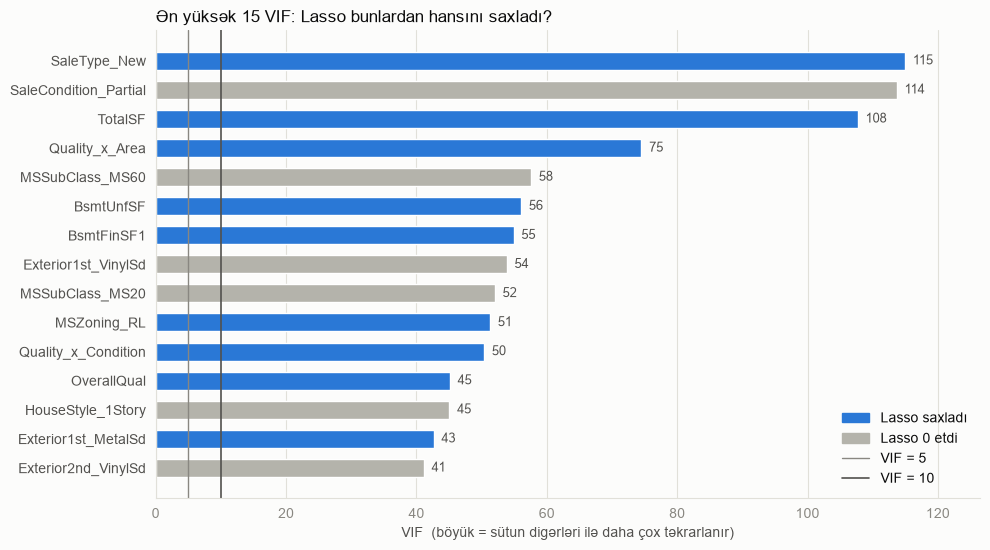

In [49]:
# ƏLAVƏ 2 / 2-ci addım: MULTİKOLLİNEARLIQ - VIF.
# VIF_j = 1 / (1 - R²_j); R²_j = j-ci sütunu QALAN sütunlarla proqnozlaşdıranda alınan R².
#   VIF ≈ 1 -> sütun digərlərindən müstəqildir | VIF > 5 -> orta | VIF > 10 -> güclü təkrarlanma (multikollinearlıq).
# Korrelyasiya matrisinin tərsinin diaqonalı eyni nəticəni verir (150 ayrı reqressiya qurmadan).
# DİQQƏT: statsmodels-in variance_inflation_factor funksiyasını istifadə etsəniz, əvvəlcə sm.add_constant(X) edin.
#         Sabit (intercept) olmasa YrSold/YearBuilt kimi sütunlar üçün VIF on minlərlə çıxır - bu, səhv ölçmədir.
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

def vif_hesabla(Xd):
    R = np.corrcoef(Xd.values.astype(float), rowvar=False)
    return pd.Series(np.diag(np.linalg.inv(R)), index=Xd.columns, name='VIF').sort_values(ascending=False)

koef = pd.Series(lasso_son.coef_, index=X_train.columns)     # 1-ci addımdakı Lasso əmsalları
saxlanan = koef.index[koef != 0]                              # Lasso-nun saxladığı sütunlar
vif = vif_hesabla(X_train)                                    # bütün sütunlar üzrə
vif_son = vif_hesabla(X_train[saxlanan])                      # yalnız Lasso-nun saxladıqları üzrə (yenidən hesablanır)

ad1 = f"Bütün {X_train.shape[1]} sütun"
ad2 = f"Lasso-nun saxladığı {len(saxlanan)} sütun"
print("=" * 70)
print(f"{'':36}{'VIF>5':>8}{'VIF>10':>9}{'maks VIF':>12}")
print("-" * 70)
print(f"{ad1:36}{(vif > 5).sum():>8}{(vif > 10).sum():>9}{vif.max():>12.1f}")
print(f"{ad2:36}{(vif_son > 5).sum():>8}{(vif_son > 10).sum():>9}{vif_son.max():>12.1f}")
print("=" * 70)

cedvel = pd.DataFrame({'VIF': vif.round(1), 'Lasso əmsalı': koef.reindex(vif.index).round(4)})
cedvel['Lasso'] = np.where(koef.reindex(vif.index) == 0, '0 etdi', 'saxladı')
print("\nƏn yüksək VIF-li 12 sütun:")
print(cedvel.head(12).to_string())

# Ən çox təkrarlanan cütlər (|r| > 0.9) və Lasso-nun onlarla nə etdiyi
korr = X_train.corr()
cutler = korr.where(np.triu(np.ones(korr.shape, dtype=bool), k=1)).stack()
cutler = cutler[cutler.abs() > 0.9].sort_values(key=np.abs, ascending=False)
fmt = lambda v: '0 (atıldı)' if v == 0 else f'{v:+.4f}'
print(f"\n|r| > 0.9 olan {len(cutler)} cüt və Lasso əmsalları (hər cütdən adətən yalnız biri qalır):")
for (a, b), r in cutler.items():
    print(f"  {a:22s} ~ {b:22s} r={r:+.3f} | Lasso: {fmt(koef[a]):>11} / {fmt(koef[b]):>11}")

# Qrafik: ən yüksək 15 VIF. Mavi = Lasso saxladı, boz = Lasso 0 etdi. Üfüqi xətlər: VIF = 5 və VIF = 10 həddləri.
FON, MAVI, BOZ = '#fcfcfb', '#2a78d6', '#b4b3ab'
YAZI, YAZI2, SONUK, TOR = '#0b0b0b', '#52514e', '#898781', '#e1e0d9'
top15 = vif.head(15).iloc[::-1]                               # ən yüksək VIF yuxarıda görünsün
with plt.rc_context({'figure.facecolor': FON, 'axes.facecolor': FON, 'axes.edgecolor': TOR,
                     'text.color': YAZI, 'axes.labelcolor': YAZI2, 'xtick.color': SONUK, 'ytick.color': YAZI2}):
    fig, ax = plt.subplots(figsize=(10, 5.6))
    ax.barh(top15.index, top15.values, height=0.62, color=[MAVI if koef[c] != 0 else BOZ for c in top15.index])
    ax.set_axisbelow(True)
    ax.xaxis.grid(True, color=TOR, linewidth=0.8)
    ax.yaxis.grid(False)
    ax.axvline(5, color=SONUK, linewidth=1)
    ax.axvline(10, color=YAZI2, linewidth=1.2)
    for i, v in enumerate(top15.values):
        ax.text(v + 1.2, i, f'{v:.0f}', va='center', fontsize=9, color=YAZI2)
    ax.set_xlim(0, top15.max() * 1.1)
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)
    ax.set_xlabel('VIF  (böyük = sütun digərləri ilə daha çox təkrarlanır)')
    ax.set_title('Ən yüksək 15 VIF: Lasso bunlardan hansını saxladı?', loc='left', fontsize=12, color=YAZI)
    ax.legend(handles=[Patch(color=MAVI, label='Lasso saxladı'), Patch(color=BOZ, label='Lasso 0 etdi'),
                       Line2D([0], [0], color=SONUK, linewidth=1, label='VIF = 5'),
                       Line2D([0], [0], color=YAZI2, linewidth=1.2, label='VIF = 10')],
              loc='lower right', frameon=False)
    fig.tight_layout()
    plt.show()

In [50]:
# ƏLAVƏ 2 / 3-cü addım: "VIF-i yüksək sütunları atsam model yaxşılaşarmı?" - təxmin etmək əvəzinə ölçək.
# VIF yalnız X-ə baxır (y-ə yox), ona görə sütun seçimi hədəfdən məlumat sızdırmır.
def vif_ile_buda(Xd, hedd):
    sutunlar = list(Xd.columns)
    while True:
        v = vif_hesabla(Xd[sutunlar])
        if v.iloc[0] < hedd:                 # hamısı həddin altındadır -> dayan
            return sutunlar
        sutunlar.remove(v.index[0])          # hər addımda ən yüksək VIF-li sütunu at

variantlar = {'Hamısı': list(X_train.columns),
              'VIF < 10': vif_ile_buda(X_train, 10),
              'VIF < 5': vif_ile_buda(X_train, 5)}

cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42)       # hər variant EYNİ 15 qatda yoxlanır (cütlənmiş müqayisə)
Xv, yv = X_train.reset_index(drop=True), y_train.reset_index(drop=True)
bal = {ad: [] for ad in variantlar}
for tr_idx, va_idx in cv.split(Xv):
    for ad, sut in variantlar.items():
        m = final_model_yarat().fit(Xv.iloc[tr_idx][sut], yv.iloc[tr_idx])
        bal[ad].append(r2_score(yv.iloc[va_idx], m.predict(Xv.iloc[va_idx][sut])))

setirler = []
for ad, sut in variantlar.items():
    r2 = np.array(bal[ad])
    d = r2 - np.array(bal['Hamısı'])
    setirler.append({'Variant': ad, 'Sütun sayı': len(sut), 'CV val R²': r2.mean(),
                     'Fərq (Hamısı-na görə)': d.mean() if ad != 'Hamısı' else 0.0,
                     '± SE': d.std(ddof=1) / np.sqrt(len(d)) if ad != 'Hamısı' else 0.0,
                     'Daha yaxşı qat': f'{(d > 0).sum()}/{len(d)}' if ad != 'Hamısı' else '-'})
print(pd.DataFrame(setirler).round(4).to_string(index=False))

atilan = [c for c in X_train.columns if c not in variantlar['VIF < 10']]
vacib = koef[atilan].abs().sort_values(ascending=False).head(6)
print("\n'VIF < 10' qaydası ilə atılan, amma Lasso-nun vacib saydığı sütunlar (Lasso əmsalı):")
print(", ".join(f"{c} ({koef[c]:+.3f})" for c in vacib.index if koef[c] != 0))

 Variant  Sütun sayı  CV val R²  Fərq (Hamısı-na görə)   ± SE Daha yaxşı qat
  Hamısı         151     0.9354                 0.0000 0.0000              -
VIF < 10         127     0.9083                -0.0271 0.0032           0/15
 VIF < 5         120     0.8780                -0.0574 0.0053           0/15

'VIF < 10' qaydası ilə atılan, amma Lasso-nun vacib saydığı sütunlar (Lasso əmsalı):
TotalSF (+0.116), Quality_x_Area (+0.068), YearBuilt (+0.053), Quality_x_Condition (+0.032), SaleType_New (+0.031), MSZoning_RL (+0.014)


(a) IQR qaydası, dollarla     : 54 ev ($337,500-dan bahalı) = 4.6%
    IQR qaydası, log-qiymətdə : 13 bahalı + 12 ucuz ev  (log bahalı tərəfdəki outlier-ləri xeyli azaldır)

(b) |z| > 3 olan sətir: 30 (2.6%) → kvadratik xətanın 29%-ni yaradır
    CV RMSE: hamısı $20,411 | outlier-siz $17,485   ||   CV MAE: hamısı $13,605 | outlier-siz $12,377

Ən böyük 10 outlier (|z| üzrə):
  Id  Faktiki  Proqnoz (CV)    z SaleCondition SaleType
 633    82500      172120.0 -9.0        Family       WD
 496    34900       76938.0 -9.0       Abnorml       WD
 463    62383      120572.0 -8.3        Normal       WD
 969    37900       70034.0 -7.8       Abnorml       WD
1325   147000      283679.0 -7.6       Partial      New
 411    60000      103299.0 -6.4       Abnorml      COD
 971   135000       80257.0  5.9       Abnorml       WD
 813    55993       74957.0 -5.1        Alloca       WD
1454    84500      127451.0 -5.0       Abnorml       WD
 875    66500       98251.0 -4.7       Abnorml       WD

SaleC

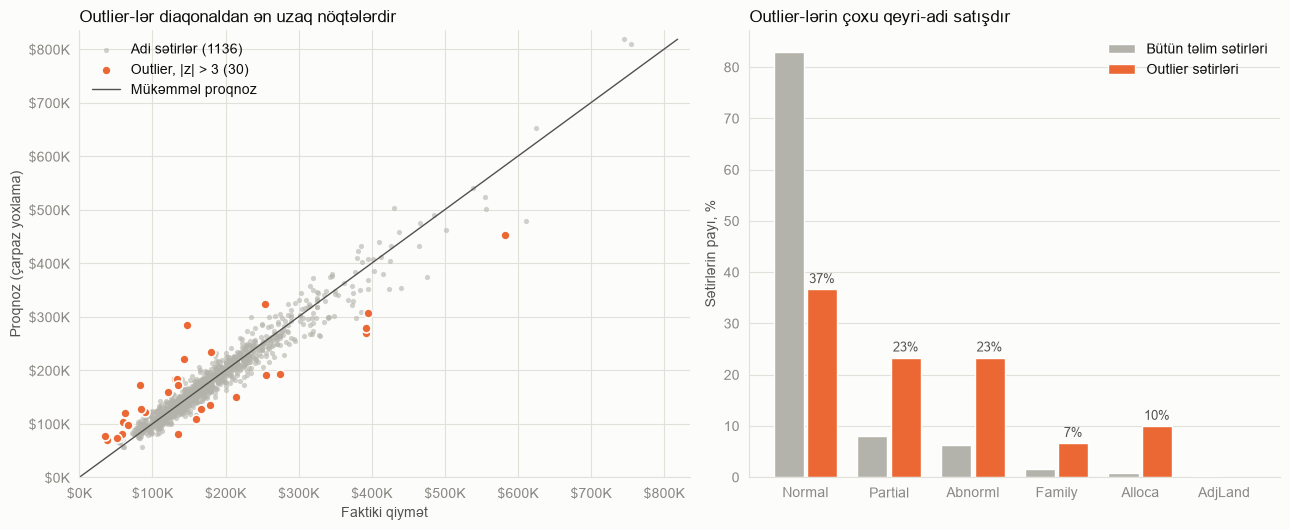

In [51]:
# ƏLAVƏ 2 / 4-cü addım: OUTLIER-ləri tapaq (silmək haqqında qərarı növbəti addımda ÖLÇÜ ilə veririk).
from sklearn.model_selection import KFold, cross_val_predict
from matplotlib.ticker import FuncFormatter

# (a) Hədəfin özündə: IQR qaydası (Q3 + 1.5*IQR-dən bahalı evlər). log1p-dən sonra bu say nə qədər dəyişir?
q1, q3 = y_train.quantile([0.25, 0.75])
bahali = int((y_train > q3 + 1.5 * (q3 - q1)).sum())
ly = np.log1p(y_train)
lq1, lq3 = ly.quantile([0.25, 0.75])
log_bahali = int((ly > lq3 + 1.5 * (lq3 - lq1)).sum())
log_ucuz = int((ly < lq1 - 1.5 * (lq3 - lq1)).sum())
print(f"(a) IQR qaydası, dollarla     : {bahali} ev (${q3 + 1.5 * (q3 - q1):,.0f}-dan bahalı) = {bahali / len(y_train) * 100:.1f}%")
print(f"    IQR qaydası, log-qiymətdə : {log_bahali} bahalı + {log_ucuz} ucuz ev  (log bahalı tərəfdəki outlier-ləri xeyli azaldır)")

# (b) Modelin xətasında: log-miqyasda qalıq = log(faktiki) - log(proqnoz).
# Robust z-skor: ortalama/std əvəzinə median/MAD (adi ortalama və std outlier-lərin özündən təsirlənir, median və MAD yox).
p_tr = final_model.predict(X_train)
qaliq = np.log1p(y_train.values) - np.log1p(p_tr)
med = np.median(qaliq)
mad = 1.4826 * np.median(np.abs(qaliq - med))
z_tr = (qaliq - med) / mad
outlier = np.abs(z_tr) > 3

# Xətanın hansı hissəsini bu sətirlər yaradır? Dürüst olsun deyə çarpaz yoxlama (OOF) proqnozlarından istifadə edirik:
# hər sətir üçün proqnozu o sətri GÖRMƏMİŞ model verir.
oof = cross_val_predict(final_model_yarat(), X_train, y_train, cv=KFold(5, shuffle=True, random_state=42))
xeta2 = (y_train.values - oof) ** 2
print(f"\n(b) |z| > 3 olan sətir: {outlier.sum()} ({outlier.mean() * 100:.1f}%) → kvadratik xətanın {xeta2[outlier].sum() / xeta2.sum() * 100:.0f}%-ni yaradır")
print(f"    CV RMSE: hamısı ${np.sqrt(xeta2.mean()):,.0f} | outlier-siz ${np.sqrt(xeta2[~outlier].mean()):,.0f}"
      f"   ||   CV MAE: hamısı ${np.abs(y_train.values - oof).mean():,.0f} | outlier-siz ${np.abs(y_train.values - oof)[~outlier].mean():,.0f}")

# Bu sətirlər kimdir? Id və satış növü oxunaqlı fayldadır (sətir sırası train_model_ready.csv ilə eynidir).
oxunaqli = pd.read_csv('train_feature_engineered.csv', usecols=['Id', 'SaleCondition', 'SaleType'])
assert len(oxunaqli) == len(df), "train_feature_engineered.csv ilə train_model_ready.csv-nin sətir sayı uyğun deyil"
info = oxunaqli.loc[y_train.index].reset_index(drop=True)
en_pis = pd.DataFrame({'Id': info['Id'], 'Faktiki': y_train.values, 'Proqnoz (CV)': oof.round(0), 'z': z_tr.round(1),
                       'SaleCondition': info['SaleCondition'], 'SaleType': info['SaleType']})[outlier]
print("\nƏn böyük 10 outlier (|z| üzrə):")
print(en_pis.reindex(en_pis['z'].abs().sort_values(ascending=False).index).head(10).to_string(index=False))

say = pd.DataFrame({'Hamısı, %': info['SaleCondition'].value_counts(normalize=True) * 100,
                    'Outlier, %': info.loc[outlier, 'SaleCondition'].value_counts(normalize=True) * 100})
say = say.fillna(0).sort_values('Hamısı, %', ascending=False)
print("\nSaleCondition payı:")
print(say.round(1).to_string())
print(f"→ Qeyri-Normal satışların payı: bütün təlim sətirlərində {100 - say.loc['Normal', 'Hamısı, %']:.0f}%, outlier-lərdə {100 - say.loc['Normal', 'Outlier, %']:.0f}%")

# Qrafik. Sol: faktiki vs CV-proqnoz (outlier-lər narıncı). Sağ: outlier-lərin satış növü.
FON, MAVI, BOZ, NARINCI = '#fcfcfb', '#2a78d6', '#b4b3ab', '#eb6834'
YAZI, YAZI2, SONUK, TOR = '#0b0b0b', '#52514e', '#898781', '#e1e0d9'
dollar_k = FuncFormatter(lambda v, _: f'${v:,.0f}K')
with plt.rc_context({'figure.facecolor': FON, 'axes.facecolor': FON, 'axes.edgecolor': TOR,
                     'text.color': YAZI, 'axes.labelcolor': YAZI2, 'xtick.color': SONUK, 'ytick.color': SONUK}):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.4), gridspec_kw={'width_ratios': [1.15, 1]})
    ax1.scatter(y_train.values[~outlier] / 1000, oof[~outlier] / 1000, s=14, color=BOZ, alpha=0.6, linewidths=0,
                label=f'Adi sətirlər ({(~outlier).sum()})')
    ax1.scatter(y_train.values[outlier] / 1000, oof[outlier] / 1000, s=42, color=NARINCI, edgecolors=FON, linewidths=1.2,
                label=f'Outlier, |z| > 3 ({outlier.sum()})', zorder=3)
    hedd = max(y_train.max(), oof.max()) / 1000
    ax1.plot([0, hedd], [0, hedd], color=YAZI2, linewidth=1, label='Mükəmməl proqnoz')
    ax1.set_xlim(0, hedd * 1.02); ax1.set_ylim(0, hedd * 1.02)
    ax1.xaxis.set_major_formatter(dollar_k); ax1.yaxis.set_major_formatter(dollar_k)
    ax1.set_xlabel('Faktiki qiymət'); ax1.set_ylabel('Proqnoz (çarpaz yoxlama)')
    ax1.set_title('Outlier-lər diaqonaldan ən uzaq nöqtələrdir', loc='left', fontsize=12, color=YAZI)
    ax1.legend(loc='upper left', frameon=False)

    x = np.arange(len(say)); w = 0.4
    ax2.bar(x - w / 2, say['Hamısı, %'], width=w - 0.04, color=BOZ, label='Bütün təlim sətirləri')
    ax2.bar(x + w / 2, say['Outlier, %'], width=w - 0.04, color=NARINCI, label='Outlier sətirləri')
    for xi, v in zip(x, say['Outlier, %']):
        if v > 0:
            ax2.text(xi + w / 2, v + 1.2, f'{v:.0f}%', ha='center', fontsize=9, color=YAZI2)
    ax2.set_xticks(x); ax2.set_xticklabels(say.index)
    ax2.set_ylabel('Sətirlərin payı, %')
    ax2.set_title('Outlier-lərin çoxu qeyri-adi satışdır', loc='left', fontsize=12, color=YAZI)
    ax2.legend(loc='upper right', frameon=False)
    for a in (ax1, ax2):
        a.set_axisbelow(True)
        a.grid(True, color=TOR, linewidth=0.8)                 # sakit, nazik tor xətləri
        for s in ('top', 'right'):
            a.spines[s].set_visible(False)
    ax2.xaxis.grid(False)
    fig.tight_layout()
    plt.show()

In [52]:
# ƏLAVƏ 2 / 5-ci addım: "Outlier ilə nə edim?" - üç yolu EYNİ 15 qatda müqayisə edək.
#   1) Heç nə etmə (olduğu kimi saxla)
#   2) SİL   : təlim qatından |z| > 3 olan sətirləri at, modeli yenidən öyrət
#   3) KƏS   : davamlı xüsusiyyətlərin 99-cu faizdən yuxarı dəyərlərini 99-cu faizə bərabərlə (winsorize)
# QAYDA: silmə/kəsmə YALNIZ təlim qatında edilir. Yoxlama qatı (val) və test dəsti olduğu kimi qalır (outlier-lər daxil).
kontinu = [c for c in X_train.columns if X_train[c].nunique() > 15]       # davamlı sütunlar (ikili/ordinal deyil)

def fit_hec_ne(Xa, ya):
    return final_model_yarat().fit(Xa, ya), (lambda Z: Z)

def fit_sil(Xa, ya, hedd=3.0):
    m1 = final_model_yarat().fit(Xa, ya)                                  # 1-ci keçid: hamısı ilə öyrət
    q = np.log1p(ya.values) - np.log1p(m1.predict(Xa))
    md = np.median(q)
    z = (q - md) / (1.4826 * np.median(np.abs(q - md)))
    qalan = np.abs(z) <= hedd
    return final_model_yarat().fit(Xa[qalan], ya[qalan]), (lambda Z: Z)   # 2-ci keçid: böyük qalıqlılar olmadan

def fit_kes(Xa, ya, faiz=0.99):
    tavan = Xa[kontinu].quantile(faiz)                                    # tavanı yalnız TƏLİM qatından öyrənirik
    kes = lambda Z: Z.assign(**{c: Z[c].clip(upper=tavan[c]) for c in kontinu})
    return final_model_yarat().fit(kes(Xa), ya), kes

usullar = {'1) Heç nə etmə': fit_hec_ne, '2) Təlimdən sil (|z|>3)': fit_sil, '3) Xüsusiyyətləri kəs (99%)': fit_kes}
cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42)
Xv, yv = X_train.reset_index(drop=True), y_train.reset_index(drop=True)
iri_hedd = X_train['TotalSF'].quantile(0.95)                              # "ən böyük 5% ev" (TotalSF üzrə) hədd
netice = {ad: {'r2': [], 'rmse': [], 'mae_iri': [], 'mae_qalan': []} for ad in usullar}
for tr_idx, va_idx in cv.split(Xv):
    Xa, ya, Xb, yb = Xv.iloc[tr_idx], yv.iloc[tr_idx], Xv.iloc[va_idx], yv.iloc[va_idx]
    iri = (Xb['TotalSF'] > iri_hedd).values
    for ad, fit_f in usullar.items():
        m, hazirla = fit_f(Xa, ya)
        p = m.predict(hazirla(Xb))                                        # yoxlama qatı DƏYİŞMİR
        netice[ad]['r2'].append(r2_score(yb, p))
        netice[ad]['rmse'].append(np.sqrt(mean_squared_error(yb, p)))
        netice[ad]['mae_iri'].append(mean_absolute_error(yb[iri], p[iri]))
        netice[ad]['mae_qalan'].append(mean_absolute_error(yb[~iri], p[~iri]))

esas = np.array(netice['1) Heç nə etmə']['r2'])
setirler = []
for ad in usullar:
    r2 = np.array(netice[ad]['r2'])
    d = r2 - esas
    setirler.append({'Üsul': ad, 'CV val R²': r2.mean(), 'CV RMSE ($)': np.mean(netice[ad]['rmse']),
                     'Fərq (1-ə görə)': d.mean(), '± SE': d.std(ddof=1) / np.sqrt(len(d)) if not ad.startswith('1') else 0.0,
                     'Daha yaxşı qat': f'{(d > 0).sum()}/{len(d)}' if not ad.startswith('1') else '-'})
print("Çarpaz yoxlama (15 qat; silmə/kəsmə yalnız təlim qatında, yoxlama qatı toxunulmaz):")
print(pd.DataFrame(setirler).round(4).to_string(index=False))

# Kəsmə niyə pisləşdirir? Xəta hansı evlərdə artır? (orta MAE, 15 qat)
print("\nOrta MAE ($): ən böyük 5% ev (TotalSF üzrə) vs qalan evlər")
for ad in usullar:
    print(f"  {ad:30s} ən böyük 5%: ${np.mean(netice[ad]['mae_iri']):>7,.0f} | qalan evlər: ${np.mean(netice[ad]['mae_qalan']):>7,.0f}")

print("\nTEST dəsti (toxunulmaz, outlier-lər daxil) - yalnız qiymətləndirmək üçün:")
for ad, fit_f in usullar.items():
    m, hazirla = fit_f(X_train, y_train)
    p = m.predict(hazirla(X_test))
    print(f"  {ad:30s} R²={r2_score(y_test, p):.4f} | RMSE=${np.sqrt(mean_squared_error(y_test, p)):,.0f} | MAE=${mean_absolute_error(y_test, p):,.0f}")

# TƏLƏ: outlier-ləri TEST dəstindən də silsək nə olur? (təlim qalıqlarının median/MAD-ı ilə eyni qaydanı test-ə tətbiq edirik)
q_tr = np.log1p(y_train.values) - np.log1p(final_model.predict(X_train))
med_tr = np.median(q_tr)
mad_tr = 1.4826 * np.median(np.abs(q_tr - med_tr))
p_te = final_model.predict(X_test)
z_te = (np.log1p(y_test.values) - np.log1p(p_te) - med_tr) / mad_tr
temiz = np.abs(z_te) <= 3
print(f"\nTƏLƏ - test dəstindən də {(~temiz).sum()} 'outlier' silsək ({len(temiz)} → {temiz.sum()} sətir):")
print(f"  Dürüst test (hamısı)   : R²={r2_score(y_test, p_te):.4f} | RMSE=${np.sqrt(mean_squared_error(y_test, p_te)):,.0f}")
print(f"  'Təmizlənmiş' test     : R²={r2_score(y_test.values[temiz], p_te[temiz]):.4f} | RMSE=${np.sqrt(mean_squared_error(y_test.values[temiz], p_te[temiz])):,.0f}"
      f"   ← şişirdilmiş: model yaxşılaşmayıb, yalnız çətin sətirləri gizlətmişik")

Çarpaz yoxlama (15 qat; silmə/kəsmə yalnız təlim qatında, yoxlama qatı toxunulmaz):
                       Üsul  CV val R²  CV RMSE ($)  Fərq (1-ə görə)   ± SE Daha yaxşı qat
             1) Heç nə etmə     0.9354   20328.4716           0.0000 0.0000              -
    2) Təlimdən sil (|z|>3)     0.9350   20378.9392          -0.0004 0.0010           7/15
3) Xüsusiyyətləri kəs (99%)     0.9141   23433.2779          -0.0212 0.0057           2/15

Orta MAE ($): ən böyük 5% ev (TotalSF üzrə) vs qalan evlər
  1) Heç nə etmə                 ən böyük 5%: $ 38,358 | qalan evlər: $ 12,336
  2) Təlimdən sil (|z|>3)        ən böyük 5%: $ 39,373 | qalan evlər: $ 12,216
  3) Xüsusiyyətləri kəs (99%)    ən böyük 5%: $ 51,606 | qalan evlər: $ 12,312

TEST dəsti (toxunulmaz, outlier-lər daxil) - yalnız qiymətləndirmək üçün:
  1) Heç nə etmə                 R²=0.9306 | RMSE=$19,585 | MAE=$13,820
  2) Təlimdən sil (|z|>3)        R²=0.9324 | RMSE=$19,327 | MAE=$13,536
  3) Xüsusiyyətləri kəs (99%)    R²=

### Nəticələr: dörd suala cavab

**1) Final model: `Lasso + log1p(hədəf)`.** Test R² ≈ **0.931**, RMSE ≈ **$19.6k** (orta qiymətin 10.8%-i), MAE ≈ **$13.8k** (7.6%-i). Lasso 151 sütundan 43-nü 0 edib, 108-ni saxlayıb. Ən güclü sütunlar `TotalSF`, `Quality_x_Area`, `YearBuilt`-dir (əmsallar standartlaşdırılmış sütunlara görədir, ona görə bir-biri ilə müqayisə olunur).

**2) Overfitting zəifdir.** Train − Test fərqi **0.02**-dir (0.2 deyil; 0.2 olsaydı ciddi overfitting olardı). Təkrarlanan CV-də fərq ≈ 0.017-dir və test R² (0.931) CV val R²-nin (0.935 ± 0.011) daxilindədir, yəni test bölgüsü nə "şanslı", nə "şanssız"dır. Baseline `LinearRegression`-da fərq 0.043 idi, log + Lasso onu təxminən yarıya endirib. Qalan kiçik fərq normaldır: istənilən model öyrəndiyi sətirləri bir az daha yaxşı bilir.

**3) VIF: multikollinearlıq VAR, amma proqnoz üçün problem deyil.**
- 151 sütunun 54-ündə VIF > 10 var (maksimum 115). İki səbəb: (i) bizim düzəltdiyimiz sütunlar öz komponentləri ilə bağlıdır (`TotalSF`, `Quality_x_Area`, `Quality_x_Condition`); (ii) eyni məlumatın iki forması (`SaleType_New` ~ `SaleCondition_Partial`, r = 0.994; `Exterior1st_*` ~ `Exterior2nd_*`; `GarageQual` ~ `GarageCond`).
- Lasso hər cütdən adətən yalnız birini saxlayır: onun saxladığı 108 sütunda VIF > 10 olan yalnız 10 sütun qalır.
- **VIF-ə görə sütun atmaq modeli pisləşdirir** (VIF < 10 qaydası: CV R² −0.027, 15 qatın hamısında pis). Çünki bu qayda ən güclü sütunları (`TotalSF`, `Quality_x_Area`, `YearBuilt`) atır.
- VIF yalnız **tək-tək əmsalları şərh edəndə** problemdir: məsələn `TotalSF`-in təsiri `Quality_x_Area` ilə bölüşülür, ona görə "1 kv.fut. qiyməti nə qədər artırır?" sualına bu əmsaldan cavab verməyin. Qiymət proqnozu üçün Lasso kifayətdir.

**4) Outlier: silməyin, model olduğu kimi yaxşıdır.**
- `|z| > 3` olan 30 sətir (2.6%) kvadratik xətanın **29%-ni** yaradır (CV RMSE $20.4k → $17.5k onlarsız). Onların **63%-i qeyri-Normal satışdır** (bütün sətirlərdə bu pay 17%-dir): qeyri-adi satış (barter, girovun tutulması, qısa satış), ailə üzvləri arasında satış, tikintisi tamamlanmamış ev. Yəni bunlar məlumat səhvi deyil, qiyməti evin xüsusiyyətlərindən çox satış şəraiti müəyyən edən real hallardır və xüsusiyyətlər bunu izah edə bilmir.
- **Təlimdən silmək** praktiki fayda vermir: CV-də fərq −0.0004 ± 0.0010 (qatların 7/15-i yaxşı), testdə +0.002. Bu qədər kiçik fərq 0.002 xəta çərçivəsindədir, sətir silməyə dəyməz.
- **Xüsusiyyətləri 99%-ə kəsmək ziyan verir:** CV-də **−0.021** (qatların 13/15-i pis). Səbəb çıxışda görünür: ən böyük 5% evdə MAE ≈ $38k-dan ≈ $52k-ya qalxır, qalan evlərdə dəyişmir (≈ $12.3k). Böyük evlər "outlier" deyil, qiymətin əsas siqnalıdır; kəsmək onların qiymətini aşağı salır. Testdə kəsmə yaxşı görünür (0.9363), amma bu yalnız bir bölgünün (292 sətir) təsadüfidir. Qərarı **CV-yə** görə verin, test nəticəsinə görə yox.
- **Test dəstindən outlier silməyin:** R² 0.9306 → 0.9405 "yaxşılaşır", amma bu şişirdilmiş rəqəmdir, model eyni modeldir.
- nb1-də ən məşhur iki outlier (`Id` 524 və 1299: 4000+ kv.fut., "Partial" satış) artıq çıxarılıb.

**Nə vaxt silmək olar?** Yalnız (a) sətir məlumat səhvidirsə (mümkünsüz dəyər) və ya (b) qərarı **qaydayla** verirsinizsə, məsələn "yalnız `SaleCondition = Normal` satışlarını modelləşdiririk", və bunu həm təlimə, həm testə eyni tətbiq edib hesabatda yazırsınızsa. Onda məsələ dəyişir: model qeyri-adi satışları proqnozlaşdırmağa çalışmır.

**Qeyd:** 0.001–0.002 səviyyəsindəki fərqlər təsadüfi dəyişkənliyin içindədir. "Hansı variant daha yaxşıdır?" sualına CV-nin cütlənmiş müqayisəsi (eyni qatlarda fərq ± SE) ilə cavab verin; variantı test dəstinə baxıb seçməyin, çünki test yalnız son qiymətləndirmə üçündür.

---
## BONUS Tapşırıq 5 (final model ilə): Kaggle test dəstində proqnozlar

Bu xanalar yuxarıdakı BONUS Tapşırıq 5-in icrasıdır, **final model (Lasso + log1p)** ilə. Addımlar:

1. **Final modeli bütün etiketli verilənlərdə (1458 sətir) yenidən öyrədin.** 80/20 bölgü modeli *qiymətləndirmək* üçün idi. Kaggle test dəstinin qiymətləri gizlidir, ona görə ayırdığımız 20% də öyrənməyə kömək edə bilər. Resept eynidir (`final_model_yarat()`), yalnız verilən çoxdur.
2. **Test üçün `test_model_ready.csv` istifadə edin, xam `test.csv`-ni yox.** Xam fayl mətn sütunları və boş dəyərlər ehtiva edir. `test_model_ready.csv` isə 1–3-cü notebook-larda təlimlə **eyni qaydada** hazırlanıb. Scaler və log çevirmə final modelin içindədir, ona görə təlimdəki ilə eynidir.
3. **Eyni sütunlar, eyni sıra:** `test_df[X_train.columns]` (151 sütun). Model sütunları adı və sırası ilə tanıyır.
4. **`Id` sırasını yoxlayın.** `test_model_ready.csv`-də `Id` yoxdur. `Id`-ləri `test.csv`-dən götürürük və sətir sırasının eyni olduğunu iki fayldakı ortaq sütunlarla yoxlayırıq (səhv sıra = hər evə başqa evin qiyməti yazılır).
5. **Təhlükəsizlik qaydası:** proqnoz təlimdəki qiymət aralığından ([min, max]) kənara çıxırsa, aralığa qaytarılır. Səbəbi aşağıdakı qeydlərdədir.

In [ ]:
# BONUS 5: Kaggle təqdimatı (FİNAL MODEL = Lasso + log1p ilə). Tapşırıq 1-10-un TODO xanalarına toxunmur.

# 1) Final modeli BÜTÜN etiketli verilənlərdə (1458 sətir) yenidən öyrət; sütunlar əvvəlki 151 sütundur.
X_hamisi, y_hamisi = X[X_train.columns], y
final_kaggle = final_model_yarat().fit(X_hamisi, y_hamisi)
print(f"Öyrədildi: {X_hamisi.shape[0]} sətir, {X_hamisi.shape[1]} sütun | Lasso alpha = {final_kaggle.regressor_[-1].alpha_:.5f}")

# 2) Test dəsti: EYNİ 151 sütun, EYNİ sıra. Id-ləri ayrıca saxla.
test_df = pd.read_csv('test_model_ready.csv')
test_features = test_df[X_train.columns]
test_ids = pd.read_csv('test.csv', usecols=['Id'])['Id']

# Yoxlamalar: sətir sayı, boş dəyər, Id sırası (test_model_ready-də Id yoxdur -> oxunaqlı fayldakı ortaq sütunlarla yoxla)
oxunaqli_test = pd.read_csv('test_feature_engineered.csv')
assert len(test_features) == len(test_ids) == len(oxunaqli_test) == 1459, "Kaggle test dəstində 1459 sətir olmalıdır"
assert not test_features.isna().any().any(), "Test xüsusiyyətlərində boş dəyər var"
assert (oxunaqli_test['Id'].values == test_ids.values).all(), "Id sırası uyğun deyil"
for sutun in ['TotalSF', 'OverallQual', 'YearBuilt', 'LotArea']:
    assert np.allclose(test_features[sutun].values, oxunaqli_test[sutun].values), f"{sutun}: sətir sırası uyğun deyil"
print("Yoxlamalar keçdi: 1459 sətir, boş dəyər yoxdur, Id və sətir sırası uyğundur.")

# 3) Proqnoz. Pipeline scaler və log çevirməni özü edir, nəticə DOLLARDIR.
xam_proqnoz = final_kaggle.predict(test_features)

# 4) Təhlükəsizlik qaydası: proqnozu təlimdəki qiymət aralığına [min, max] sal.
alt, ust = y_hamisi.min(), y_hamisi.max()
test_predictions = np.clip(xam_proqnoz, alt, ust)
kenara_cixan = np.flatnonzero(xam_proqnoz != test_predictions)
print(f"\nTəlim qiymət aralığı: ${alt:,.0f} - ${ust:,.0f} | bu aralıqdan kənara çıxan proqnoz: {len(kenara_cixan)}")
for i in kenara_cixan:
    print(f"  Id {test_ids.iloc[i]}: xam proqnoz ${xam_proqnoz[i]:,.0f} → ${test_predictions[i]:,.0f}")

# 5) Təqdimat DataFrame-i: Id və SalePrice
submission = pd.DataFrame({'Id': test_ids, 'SalePrice': test_predictions})
assert submission['SalePrice'].notna().all() and (submission['SalePrice'] > 0).all()

# 6) Formatı Kaggle-ın nümunəsi ilə yoxla, sonra yadda saxla
numune = pd.read_csv('sample_submission.csv')
assert list(submission.columns) == list(numune.columns) and (submission['Id'].values == numune['Id'].values).all()
submission.to_csv('submission.csv', index=False)
print(f"\nsubmission.csv yazıldı: {submission.shape[0]} sətir, sütunlar {list(submission.columns)}")
print(submission.head())

Öyrədildi: 1458 sətir, 151 sütun | Lasso alpha = 0.00063
Yoxlamalar keçdi: 1459 sətir, boş dəyər yoxdur, Id və sətir sırası uyğundur.

Təlim qiymət aralığı: $34,900 - $755,000 | bu aralıqdan kənara çıxan proqnoz: 1
  Id 2550: xam proqnoz $1,702,137 → $755,000

submission.csv yazıldı: 1459 sətir, sütunlar ['Id', 'SalePrice']
     Id      SalePrice
0  1461  116842.697473
1  1462  153888.813642
2  1463  181516.980674
3  1464  201276.827172
4  1465  196877.765152


In [ ]:
# BONUS 5 / Təhlil üçün faktlar. Aşağıdakı rəqəmlərə baxıb təhlil suallarını ÖZ sözlərinizlə cavablandırın.
from sklearn.model_selection import KFold, cross_val_predict

# (a) Proqnoz aralığı: təlim qiymətləri ilə müqayisə
muqayise = pd.DataFrame({'Təlim SalePrice': y_hamisi.describe(percentiles=[0.25, 0.5, 0.75]),
                         'Test proqnozu': submission['SalePrice'].describe(percentiles=[0.25, 0.5, 0.75])}).drop('count')
print(muqayise.to_string(float_format='{:,.0f}'.format))

# (b) Ən yüksək və ən aşağı proqnozlu evlər
melumat = oxunaqli_test[['Id', 'Neighborhood', 'OverallQual', 'YearBuilt', 'TotalSF', 'SaleCondition']].copy()
melumat['Proqnoz'] = submission['SalePrice'].values
print("\nƏn BAHALI 5 ev:")
print(melumat.nlargest(5, 'Proqnoz').to_string(index=False, float_format='{:,.0f}'.format))
print("\nƏn UCUZ 5 ev:")
print(melumat.nsmallest(5, 'Proqnoz').to_string(index=False, float_format='{:,.0f}'.format))

# (c) Əminlik: çarpaz yoxlamada (hər ev üçün proqnozu o evi GÖRMƏMİŞ model verir) mütləq faiz xətası
oof = cross_val_predict(final_model_yarat(), X_hamisi, y_hamisi, cv=KFold(5, shuffle=True, random_state=42))
xeta = np.abs(y_hamisi.values - oof) / y_hamisi.values * 100
print(f"\nƏminlik (çarpaz yoxlama, {len(xeta)} ev): median xəta {np.median(xeta):.1f}%, orta xəta {xeta.mean():.1f}%")
print(f"  Evlərin 50% / 80% / 90%-i proqnozdan ± {np.percentile(xeta, 50):.0f}% / {np.percentile(xeta, 80):.0f}% / {np.percentile(xeta, 90):.0f}% daxilindədir; "
      f"{(xeta > 20).mean() * 100:.0f}%-i 20%-dən çox səhv edir")

# (d) Daha az etibarlı evlər: xüsusiyyətlərindən biri təlim aralığından kənardadır (model belə evi görməyib)
alt_x, ust_x = X_hamisi.min(), X_hamisi.max()
kenar_x = ((test_features < alt_x) | (test_features > ust_x)).any(axis=1)
print(f"\nƏn azı bir xüsusiyyəti təlim aralığından kənar olan test evi: {kenar_x.sum()} / {len(test_features)}")
print(f"Ən böyük TotalSF: test {test_features['TotalSF'].max():,.0f} | təlim {X_hamisi['TotalSF'].max():,.0f}")

      Təlim SalePrice  Test proqnozu
mean          180,933        178,447
std            79,495         79,221
min            34,900         43,241
25%           129,925        125,739
50%           163,000        156,693
75%           214,000        212,161
max           755,000        755,000

Ən BAHALI 5 ev:
  Id Neighborhood  OverallQual  YearBuilt  TotalSF SaleCondition  Proqnoz
2550      Edwards           10       2008   10,190       Partial  755,000
2629      StoneBr           10       2006    4,918       Partial  572,235
1975      NridgHt           10       2003    5,005        Normal  568,109
2683      NoRidge            9       1993    5,233        Normal  549,558
1664      NridgHt           10       2007    5,304        Normal  548,344

Ən UCUZ 5 ev:
  Id Neighborhood  OverallQual  YearBuilt  TotalSF SaleCondition  Proqnoz
2892       IDOTRR            3       1945      729       Abnorml   43,241
1823       IDOTRR            3       1900    1,042       Abnorml   44,975
1820  

### Nəticəni oxumaq üçün qeydlər (BONUS 5)

- **`submission.csv`** layihə qovluğunda yaranıb: `Id`, `SalePrice` sütunları, 1459 sətir (Kaggle-ın `sample_submission.csv` ilə eyni format). İstəsəniz Kaggle-a yükləyə bilərsiniz.
- **Niyə final modeli yenidən öyrətdik?** Test bölgüsü modeli qiymətləndirmək üçün idi. Yekun təqdimat üçün bütün etiketli sətirlərdən istifadə etmək adətən bir az daha yaxşıdır. `alpha`-nı çarpaz yoxlama yenidən seçir.
- **`Id` 2550 niyə aralığa salındı?** Bu ev test dəstinin ən böyük evidir (`TotalSF` 10,190; təlimdəki ən böyüyü 6,872) və təlimdə belə ev yoxdur. Model xəttidir: "daha böyük + daha keyfiyyətli = daha bahalı" qaydasını bu ölçüyə qədər uzadır və təxminən $1.7M proqnoz verir, halbuki təlimdəki ən bahalı ev $755k-dir. Eyni profildəki (Edwards, keyfiyyət 10, 2007–2008, `New` + `Partial` satış, 4000+ kv.fut.) iki təlim evi (`Id` 524 və 1299) nb1-də outlier kimi çıxarılmışdı və onlar cəmi $184,750 və $160,000-a satılıb. Aralığa salmaq yalnız ən absurd cavabın qarşısını alır; bu evin həqiqi qiymətini bilmirik və bu proqnoza etibar etmək olmaz.
- **Test dəstindən heç bir sətri silmək olmaz:** Kaggle bütün 1459 ev üçün proqnoz gözləyir. Outlier test sətirləri ilə yalnız proqnozu mühafizə etmək (yuxarıdakı kimi) və onu təhlildə qeyd etmək olar.
- **Təhlil sualları üçün** yuxarıdakı faktlara baxın: aralıq (a), ən bahalı/ən ucuz evlər (b), çarpaz yoxlama xətası (c) və təlim aralığından kənar evlər (d). "Nə dərəcədə əminsiniz?" sualına (c) və (d) cavab verir: xəta ümumilikdə nə qədərdir və hansı evlər üçün daha az əminsiniz?

---
## Təqdimat Yoxlama Siyahısı

Notebook-unuzun aşağıdakıları ehtiva etdiyindən əmin olun:

- ✓ Bütün tələb olunan kitabxanalar idxal edilib
- ✓ Verilənlər yüklənib və araşdırılıb
- ✓ Xüsusiyyətlər və hədəf dəyişən düzgün ayrılıb
- ✓ Verilənlər təlim (80%) və test (20%) dəstlərinə bölünüb
- ✓ Xətti Reqressiya modeli öyrədilib
- ✓ Hər iki verilənlər dəsti üzərində proqnozlar verilib
- ✓ Qiymətləndirmə metrikləri hesablanıb (MSE, RMSE, MAE, R²)
- ✓ Vizuallaşdırmalar yaradılıb (Faktiki və Proqnozlaşdırılan, Qalıqlar, Paylanma)
- ✓ Qalıqların təhlili aparılıb
- ✓ Bütün 6 təhlil sualı cavablandırılıb
- ✓ Notebook boyunca aydın sənədləşdirmə və şərhlər mövcuddur

## Əsas Nəticələr

1. **Xətti Reqressiya** reqressiya tapşırıqları üçün fundamental nəzarətli öyrənmə (supervised learning) alqoritmidir
2. **Train-test bölgüsü** verilənlərin sızmasının (data leakage) qarşısını alır və ümumiləşdirməni düzgün qiymətləndirir
3. **Çoxsaylı metriklər** (RMSE, MAE, R²) performansa fərqli baxış bucaqları təqdim edir
4. **Qalıqların təhlili** modelinizin qaçırdığı sistematik qanunauyğunluqları üzə çıxarır
5. **Təlim/test qiymətlərinin müqayisəsi** modelinizin overfitting edib-etmədiyini göstərir
6. **Vizuallaşdırma** modelin davranışını və xətalarını anlamaq üçün çox vacibdir